In [1]:
# Purpose: Import libraries for Punjab-wide geospatial data acquisition.

import requests
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path("..")
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Environment ready.")

Environment ready.


In [3]:
# Purpose: Retrieve the latest Pakistan ADM2 boundary download information.

api_url = "https://www.geoboundaries.org/api/current/gbOpen/PAK/ADM2/"

response = requests.get(api_url, timeout=60)
response.raise_for_status()

boundary_info = response.json()

print("Boundary:", boundary_info["boundaryName"])
print("Administrative level:", boundary_info["boundaryType"])
print("Year represented:", boundary_info["boundaryYearRepresented"])
print("Number of administrative units:", boundary_info["admUnitCount"])
print("Source:", boundary_info["boundarySource"])
print("License:", boundary_info["boundaryLicense"])

Boundary: Pakistan
Administrative level: ADM2
Year represented: 2019
Number of administrative units: 126
Source: geoBoundaries, Wikipedia
License: Public Domain


In [4]:
# Purpose: Download Pakistan's district boundaries as a GeoJSON file.

geojson_url = boundary_info["gjDownloadURL"]

boundary_response = requests.get(geojson_url, timeout=120)
boundary_response.raise_for_status()

pakistan_districts = gpd.read_file(
    boundary_response.content
)

pakistan_path = RAW_DIR / "pakistan_districts.geojson"

pakistan_districts.to_file(
    pakistan_path,
    driver="GeoJSON"
)

print("Downloaded successfully.")
print("Shape:", pakistan_districts.shape)
print("CRS:", pakistan_districts.crs)
print("Saved at:", pakistan_path)
print("\nAvailable columns:")
print(pakistan_districts.columns.tolist())

Downloaded successfully.
Shape: (126, 6)
CRS: EPSG:4326
Saved at: ..\data\raw\pakistan_districts.geojson

Available columns:
['shapeName', 'shapeISO', 'shapeID', 'shapeGroup', 'shapeType', 'geometry']


In [5]:
# Purpose: Inspect district names to identify Punjab's administrative units.

district_names = sorted(pakistan_districts["shapeName"].unique())

print("Total districts:", len(district_names))

for district in district_names:
    print(district)
    

Total districts: 126
Abbottabad
Astore
Attock
Awaran
Azad Kashmir
Badin
Bahawalnagar
Bahawalpur
Bajaur
Bannu
Barkhan
Battagram
Bhakkar
Buner
Chagai
Chakwal
Charsadda
Chitral
Dadu
Dera Bugti
Dera Ghazi Khan
Dera Ismail Khan
Diamer
Faisalabad
Ghanche
Ghizer
Ghotki
Gilgit
Gujranwala
Gujrat
Gwadar
Hafizabad
Hangu
Haripur
Hunza
Hyderabad
Islamabad Capital Territory
Jacobabad
Jafarabad
Jamshoro
Jhal Magsi
Jhang
Jhelum
Kachhi
Kalat
Karachi
Karak
Kashmore
Kasur
Kech
Khairpur
Khanewal
Kharan
Kharmang
Khushab
Khuzdar
Khyber
Kohat
Kohistan
Kohlu
Kurram
Lahore
Lakki Marwat
Lasbela
Layyah
Lodhran
Loralai
Lower Dir
Malakand
Mandi Bahauddin
Mansehra
Mardan
Mastung
Matiari
Mianwali
Mirpurkhas
Mohmand
Multan
Musakhel
Muzaffargarh
Nagar
Narowal
Nasirabad
Naushehro Feroze
Nawabshah
North Waziristan
Nowshera
Nushki
Okara
Orakzai
Pakpattan
Panjgur
Peshawar
Pishin
Qambar Shahdadkot
Qilla Abdullah
Qilla Saifullah
Quetta
Rahim Yar Khan
Rajanpur
Rawalpindi
Sahiwal
Sanghar
Sargodha
Shangla
Sheikhpura
Shigar
Shi

In [6]:
# Purpose: Filter Punjab districts from Pakistan's administrative boundaries.

punjab_districts = pakistan_districts[
    pakistan_districts["shapeName"].isin([
        "Attock", "Bahawalnagar", "Bahawalpur", "Bhakkar",
        "Chakwal", "Chiniot", "Dera Ghazi Khan", "Faisalabad",
        "Gujranwala", "Gujrat", "Hafizabad", "Jhang",
        "Jhelum", "Kasur", "Khanewal", "Khushab",
        "Lahore", "Layyah", "Lodhran", "Mandi Bahauddin",
        "Mianwali", "Multan", "Muzaffargarh", "Narowal",
        "Nankana Sahib", "Okara", "Pakpattan", "Rahim Yar Khan",
        "Rajanpur", "Rawalpindi", "Sahiwal", "Sargodha",
        "Sheikhpura", "Sialkot", "Toba Tek Singh", "Vehari"
    ])
].copy()

print("Punjab districts found:", len(punjab_districts))
print("\nDistricts:")
print(sorted(punjab_districts["shapeName"].tolist()))

Punjab districts found: 33

Districts:
['Attock', 'Bahawalnagar', 'Bahawalpur', 'Bhakkar', 'Chakwal', 'Dera Ghazi Khan', 'Faisalabad', 'Gujranwala', 'Gujrat', 'Hafizabad', 'Jhang', 'Jhelum', 'Kasur', 'Khanewal', 'Khushab', 'Lahore', 'Layyah', 'Lodhran', 'Mandi Bahauddin', 'Mianwali', 'Multan', 'Muzaffargarh', 'Narowal', 'Okara', 'Pakpattan', 'Rahim Yar Khan', 'Rajanpur', 'Rawalpindi', 'Sahiwal', 'Sargodha', 'Sheikhpura', 'Sialkot', 'Toba Tek Singh']


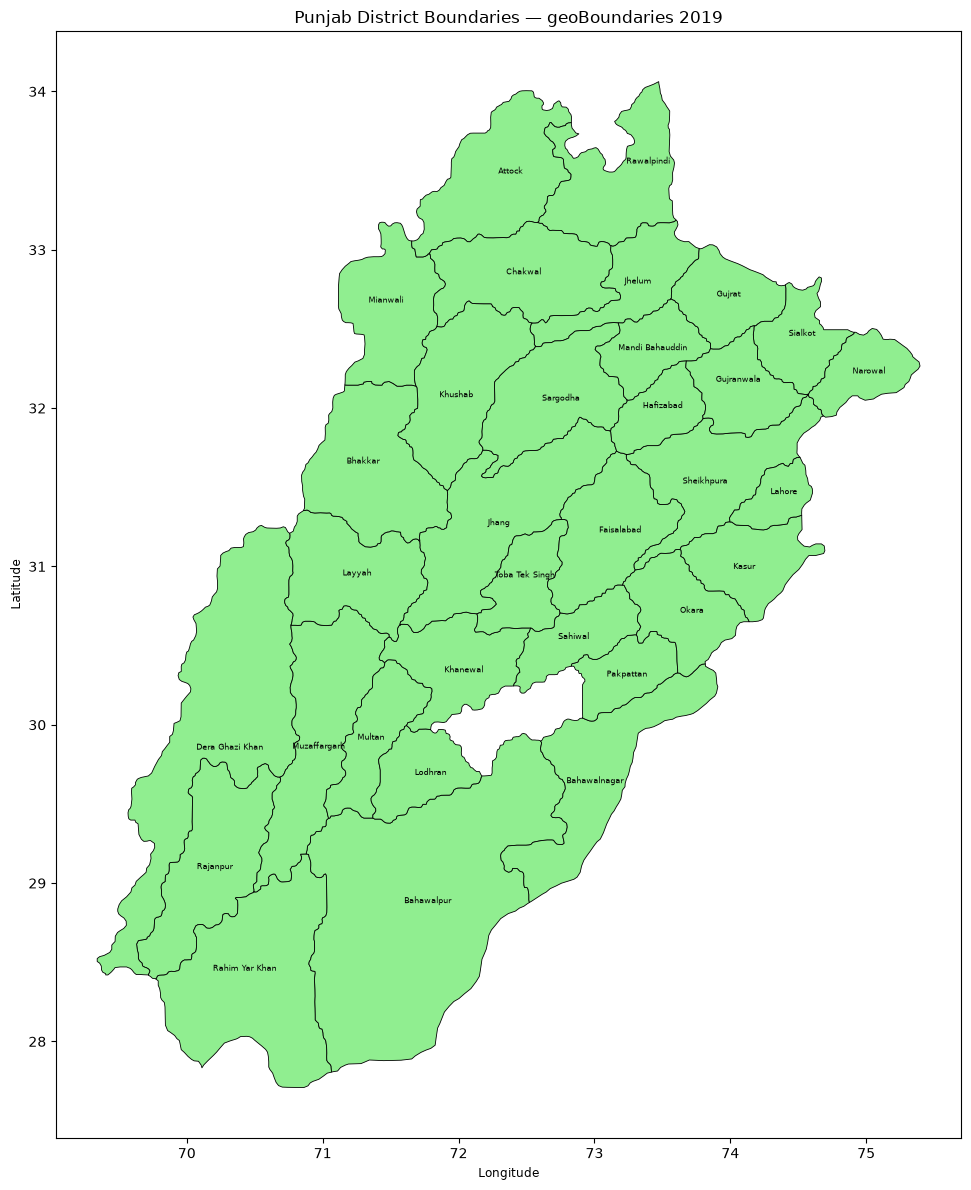

In [7]:
# Purpose: Visualize the extracted Punjab district boundaries.

fig, ax = plt.subplots(figsize=(12, 12))

punjab_districts.plot(
    ax=ax,
    edgecolor="black",
    facecolor="lightgreen",
    linewidth=0.6
)

for _, row in punjab_districts.iterrows():
    point = row.geometry.representative_point()
    ax.annotate(
        row["shapeName"],
        (point.x, point.y),
        fontsize=6,
        ha="center"
    )

ax.set_title("Punjab District Boundaries — geoBoundaries 2019")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

In [8]:
# Purpose: Check the Punjab boundary geometries and identify possible gaps.

print("Total polygons:", len(punjab_districts))
print("Invalid geometries:", (~punjab_districts.geometry.is_valid).sum())
print("Empty geometries:", punjab_districts.geometry.is_empty.sum())

print("\nGeometry types:")
print(punjab_districts.geometry.geom_type.value_counts())

print("\nDistricts with invalid geometry:")
print(
    punjab_districts.loc[
        ~punjab_districts.geometry.is_valid,
        "shapeName"
    ].tolist()
)

print("\nTotal bounds:")
print(punjab_districts.total_bounds)

Total polygons: 33
Invalid geometries: 0
Empty geometries: 0

Geometry types:
Polygon    33
Name: count, dtype: int64

Districts with invalid geometry:
[]

Total bounds:
[69.34051583 27.70896634 75.39611235 34.06215042]


In [9]:
# Purpose: Add the missing Vehari district using its source spelling.

vehari_boundary = pakistan_districts[
    pakistan_districts["shapeName"] == "Vihari"
].copy()

vehari_boundary["shapeName"] = "Vehari"

punjab_districts = gpd.GeoDataFrame(
    pd.concat(
        [punjab_districts, vehari_boundary],
        ignore_index=True
    ),
    crs=pakistan_districts.crs
)

print("District count:", len(punjab_districts))
print("Vehari included:", "Vehari" in punjab_districts["shapeName"].values)

District count: 34
Vehari included: True


In [10]:
# Purpose: Search the original boundary dataset for Chiniot and Nankana Sahib.

for name in ["Chiniot", "Nankana Sahib", "Nankana", "Nankana Sahib District"]:
    matches = pakistan_districts[
        pakistan_districts["shapeName"].str.contains(
            name, case=False, na=False
        )
    ]

    print(f"\nSearch: {name}")
    print(matches["shapeName"].tolist())


Search: Chiniot
[]

Search: Nankana Sahib
[]

Search: Nankana
[]

Search: Nankana Sahib District
[]


In [11]:
# Purpose: Calculate the total geographic coverage of the 34 Punjab districts.

punjab_projected = punjab_districts.to_crs(epsg=32643)

punjab_union = punjab_projected.geometry.union_all()

print("District count:", len(punjab_projected))
print("Combined area (km²):", round(punjab_union.area / 1_000_000, 2))
print("Combined boundary valid:", punjab_union.is_valid)
print("Combined geometry type:", punjab_union.geom_type)


District count: 34
Combined area (km²): 202221.49
Combined boundary valid: True
Combined geometry type: Polygon


In [12]:
# Purpose: Identify gaps and overlaps between the extracted district boundaries.

district_union = punjab_projected.geometry.union_all()

individual_area = punjab_projected.geometry.area.sum()
combined_area = district_union.area

overlap_area = individual_area - combined_area

print("Sum of individual district areas (km²):",
      round(individual_area / 1_000_000, 2))

print("Combined union area (km²):",
      round(combined_area / 1_000_000, 2))

print("Overlapping area (km²):",
      round(overlap_area / 1_000_000, 4))

Sum of individual district areas (km²): 202221.49
Combined union area (km²): 202221.49
Overlapping area (km²): -0.0


In [18]:
# Purpose: Find the downloaded GADM file inside the project directory.

from pathlib import Path

project_path = Path.cwd()

print("Current notebook directory:", project_path)

for file in project_path.rglob("gadm41_PAK_2*"):
    print("Found:", file.resolve())

Current notebook directory: d:\SoilSenseAI\notebooks


In [19]:
# Purpose: Check whether the GADM file exists in the project's raw data folder.

from pathlib import Path

raw_folder = Path(r"D:\SoilSenseAI\data\raw")

print("Folder exists:", raw_folder.exists())

if raw_folder.exists():
    for file in raw_folder.iterdir():
        print(file.name)

Folder exists: True
.gitkeep
gadm41_PAK_2.json
out.tif
pakistan_districts.geojson
sahiwal_cec_0-5cm_mean.tif
sahiwal_clay_0-5cm_mean.tif
sahiwal_nitrogen_0-5cm_mean.tif
sahiwal_phh2o_0-5cm_mean.tif
sahiwal_phh2o_0-5cm_Q0.5.tif
sahiwal_phh2o_0-5cm_uncertainty.tif
sahiwal_ph_0-5cm_mean.tif
sahiwal_sand_0-5cm_mean.tif
sahiwal_silt_0-5cm_mean.tif
sahiwal_soc_0-5cm_mean.tif
website_ph_uncertainty.tif


In [20]:
# Purpose: Load the GADM district boundary dataset.

gadm_districts = gpd.read_file(
    r"D:\SoilSenseAI\data\raw\gadm41_PAK_2.json"
)

print("Total districts:", len(gadm_districts))
print("Columns:", gadm_districts.columns.tolist())

display(gadm_districts.head())


Total districts: 32
Columns: ['GID_2', 'GID_0', 'COUNTRY', 'GID_1', 'NAME_1', 'NL_NAME_1', 'NAME_2', 'VARNAME_2', 'NL_NAME_2', 'TYPE_2', 'ENGTYPE_2', 'CC_2', 'HASC_2', 'geometry']


,GID_2,GID_0,COUNTRY,GID_1,NAME_1,NL_NAME_1,NAME_2,VARNAME_2,NL_NAME_2,TYPE_2,ENGTYPE_2,CC_2,HASC_2,geometry
0,Z06.1.1_1,Z06,Pakistan,Z06.1_1,AzadKashmir,NA,AzadKashmir,NA,NA,Division,Division,NA,PK.JK.JK,"MULTIPOLYGON (((73.8202 33.0173, 73.7882 33.00..."
1,PAK.2.1_1,PAK,Pakistan,PAK.2_1,Balochistan,NA,Kalat,NA,NA,Division,Division,NA,PK.BA.KL,"MULTIPOLYGON (((66.3651 25.546, 66.3637 25.544..."
2,PAK.2.2_1,PAK,Pakistan,PAK.2_1,Balochistan,NA,Makran,NA,NA,Division,Division,NA,PK.BA.MR,"MULTIPOLYGON (((63.8557 25.1268, 63.8649 25.12..."
3,PAK.2.3_1,PAK,Pakistan,PAK.2_1,Balochistan,NA,Nasirabad,NA,NA,Division,Division,NA,PK.BA.NS,"MULTIPOLYGON (((68.5603 28.5912, 68.6497 28.54..."
4,PAK.2.4_1,PAK,Pakistan,PAK.2_1,Balochistan,NA,Quetta,NA,NA,Division,Division,NA,PK.BA.QE,"MULTIPOLYGON (((62.7063 29.3985, 62.7677 29.40..."


In [21]:
# Purpose: Inspect all GADM administrative units belonging to Punjab.

print("Administrative unit types:")
print(gadm_districts["TYPE_2"].value_counts(dropna=False))

print("\nPunjab administrative units:")
punjab_gadm = gadm_districts[
    gadm_districts["NAME_1"].str.contains(
        "Punjab", case=False, na=False
    )
].copy()

print("Total Punjab records:", len(punjab_gadm))

display(
    punjab_gadm[
        ["NAME_1", "NAME_2", "TYPE_2", "ENGTYPE_2"]
    ].sort_values("NAME_2")
)

Administrative unit types:
TYPE_2
Division    32
Name: count, dtype: int64

Punjab administrative units:
Total Punjab records: 8


,NAME_1,NAME_2,TYPE_2,ENGTYPE_2
18,Punjab,Bahawalpur,Division,Division
19,Punjab,DeraGhaziKhan,Division,Division
20,Punjab,Faisalabad,Division,Division
21,Punjab,Gujranwala,Division,Division
22,Punjab,Lahore,Division,Division
23,Punjab,Multan,Division,Division
24,Punjab,Rawalpindi,Division,Division
25,Punjab,Sargodha,Division,Division


In [25]:
# Purpose: Locate the extracted Pakistan ADM2 GeoJSON file.

from pathlib import Path

search_folder = Path(r"D:\SoilSenseAI\data\raw")

matches = list(search_folder.rglob("pak_admin2_em.geojson"))

print("Files found:", len(matches))

for file in matches:
    print(file.resolve())

Files found: 1
D:\SoilSenseAI\data\raw\pak_admin_boundaries.geojson\pak_admin2_em.geojson


In [26]:
# Purpose: Load Pakistan's ADM2 district boundaries.

gadm_pak_adm2 = gpd.read_file(
    r"D:\SoilSenseAI\data\raw\pak_admin_boundaries.geojson\pak_admin2_em.geojson"
)

print("Total administrative units:", len(gadm_pak_adm2))
print("Columns:", gadm_pak_adm2.columns.tolist())

display(gadm_pak_adm2.head())

Total administrative units: 160
Columns: ['adm2_name', 'adm2_name1', 'adm2_name2', 'adm2_name3', 'adm2_pcode', 'adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'valid_on', 'valid_to', 'area_sqkm', 'version', 'lang', 'lang1', 'lang2', 'lang3', 'center_lat', 'center_lon', 'geometry']


,adm2_name,adm2_name1,adm2_name2,adm2_name3,adm2_pcode,adm1_name,adm1_name1,adm1_name2,adm1_name3,adm1_pcode,...,valid_to,area_sqkm,version,lang,lang1,lang2,lang3,center_lat,center_lon,geometry
0,Bagh,None,None,None,PK101,Azad Kashmir,None,None,None,PK1,...,None,694.415979,v01,en,None,None,None,34.003460,73.731377,"POLYGON ((73.53892 34.12617, 73.53743 34.12745..."
1,Bhimber,None,None,None,PK102,Azad Kashmir,None,None,None,PK1,...,None,1212.968878,v01,en,None,None,None,33.014136,74.150256,"POLYGON ((73.96443 33.24121, 73.96295 33.24358..."
2,Jhelum Valley,None,None,None,PK103,Azad Kashmir,None,None,None,PK1,...,None,681.765079,v01,en,None,None,None,34.188101,73.796669,"POLYGON ((73.91993 34.34231, 73.91692 34.34461..."
3,Haveli,None,None,None,PK104,Azad Kashmir,None,None,None,PK1,...,None,550.893049,v01,en,None,None,None,33.935042,74.119845,"POLYGON ((74.15687 34.04042, 74.14922 34.04302..."
4,Kotli,None,None,None,PK105,Azad Kashmir,None,None,None,PK1,...,None,1599.114841,v01,en,None,None,None,33.454265,73.946881,"POLYGON ((73.62197 33.65854, 73.62134 33.65863..."


In [27]:
# Purpose: Identify the exact province names in the ADM2 dataset.

print(
    gadm_pak_adm2["adm1_name"]
    .value_counts(dropna=False)
)

adm1_name
Punjab                36
Balochistan           35
Khyber Pakhtunkhwa    35
Sindh                 29
Gilgit Baltistan      14
Azad Kashmir          10
Islamabad              1
Name: count, dtype: int64


In [28]:
# Purpose: Extract all 36 Punjab district boundaries.

punjab_districts = gadm_pak_adm2[
    gadm_pak_adm2["adm1_name"] == "Punjab"
].copy()

print("Punjab district count:", len(punjab_districts))
print("\nDistrict names:")

print(
    punjab_districts["adm2_name"]
    .sort_values()
    .to_list()
)

Punjab district count: 36

District names:
['Attock', 'Bahawalnagar', 'Bahawalpur', 'Bhakkar', 'Chakwal', 'Chiniot', 'Dera Ghazi Khan', 'Faisalabad', 'Gujranwala', 'Gujrat', 'Hafizabad', 'Jhang', 'Jhelum', 'Kasur', 'Khanewal', 'Khushab', 'Lahore', 'Leiah', 'Lodhran', 'Mandi Bahauddin', 'Mianwali', 'Multan', 'Muzaffargarh', 'Nankana Sahib', 'Narowal', 'Okara', 'Pakpattan', 'Rahim Yar Khan', 'Rajanpur', 'Rawalpindi', 'Sahiwal', 'Sargodha', 'Sheikhupura', 'Sialkot', 'Toba Tek Singh', 'Vehari']


In [29]:
# Purpose: Validate the 36 Punjab district geometries.

print("CRS:", punjab_districts.crs)
print("Total districts:", len(punjab_districts))
print("Invalid geometries:", (~punjab_districts.geometry.is_valid).sum())
print("Empty geometries:", punjab_districts.geometry.is_empty.sum())
print("Missing district names:", punjab_districts["adm2_name"].isna().sum())

punjab_projected = punjab_districts.to_crs(epsg=32643)

print(
    "Total area (km²):",
    round(punjab_projected.geometry.area.sum() / 1_000_000, 2)
)

CRS: EPSG:4326
Total districts: 36
Invalid geometries: 0
Empty geometries: 0
Missing district names: 0
Total area (km²): 205549.55


In [30]:
# Purpose: Standardize district names and save the validated Punjab boundaries.

punjab_districts.loc[
    punjab_districts["adm2_name"] == "Leiah",
    "adm2_name"
] = "Layyah"

output_path = r"D:\SoilSenseAI\data\processed\punjab_districts.geojson"

punjab_districts.to_file(
    output_path,
    driver="GeoJSON"
)

print("Saved successfully:", output_path)
print("District count:", len(punjab_districts))

Saved successfully: D:\SoilSenseAI\data\processed\punjab_districts.geojson
District count: 36


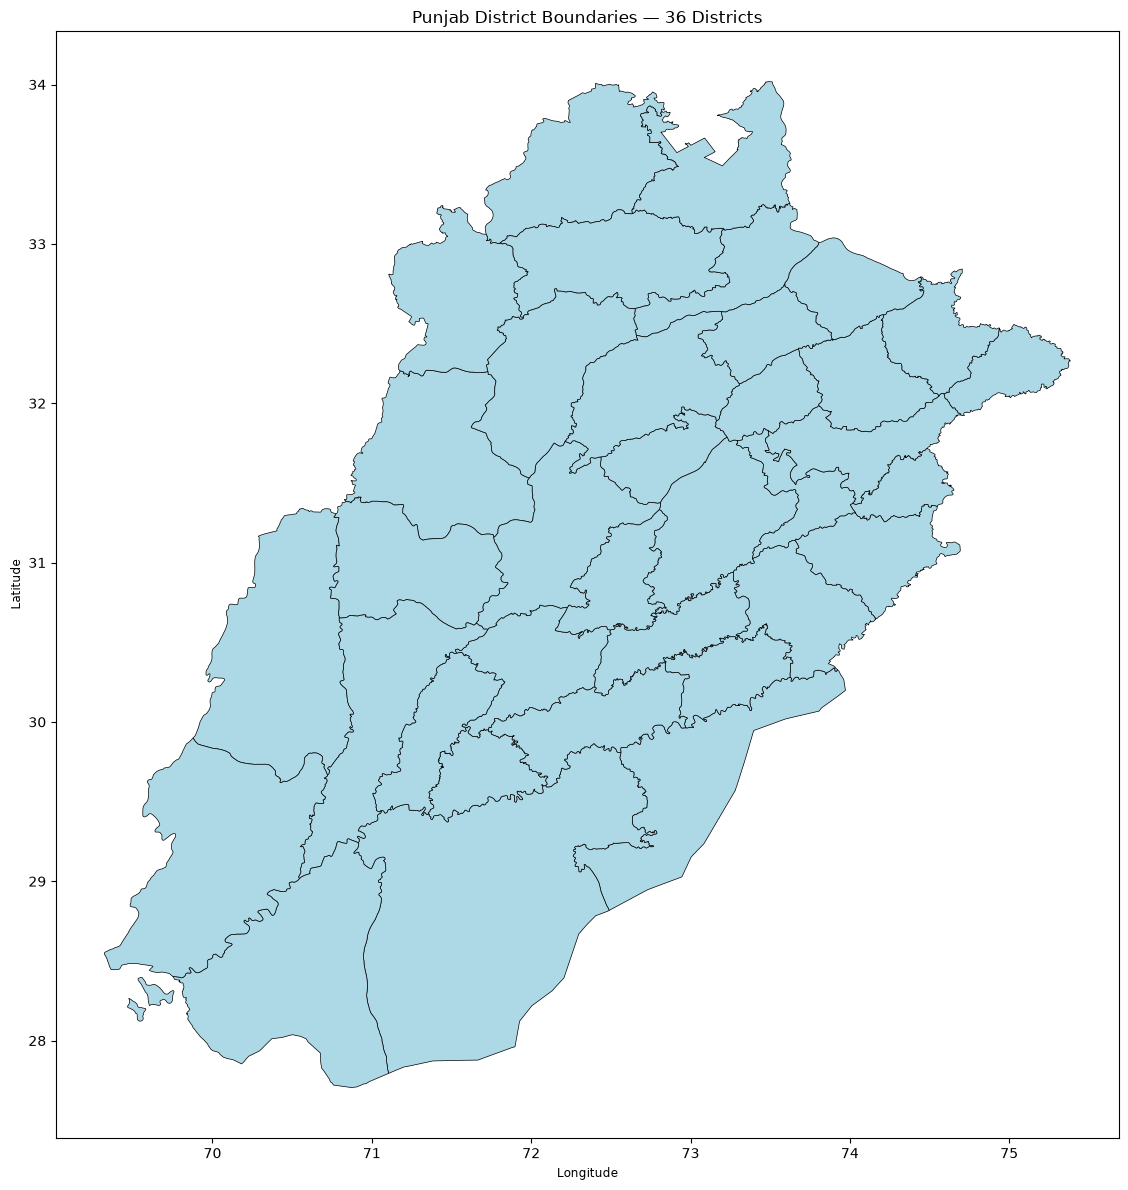

In [31]:
# Purpose: Visualize all 36 Punjab district boundaries.

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 12))

punjab_districts.plot(
    ax=ax,
    facecolor="lightblue",
    edgecolor="black",
    linewidth=0.5
)

ax.set_title("Punjab District Boundaries — 36 Districts")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

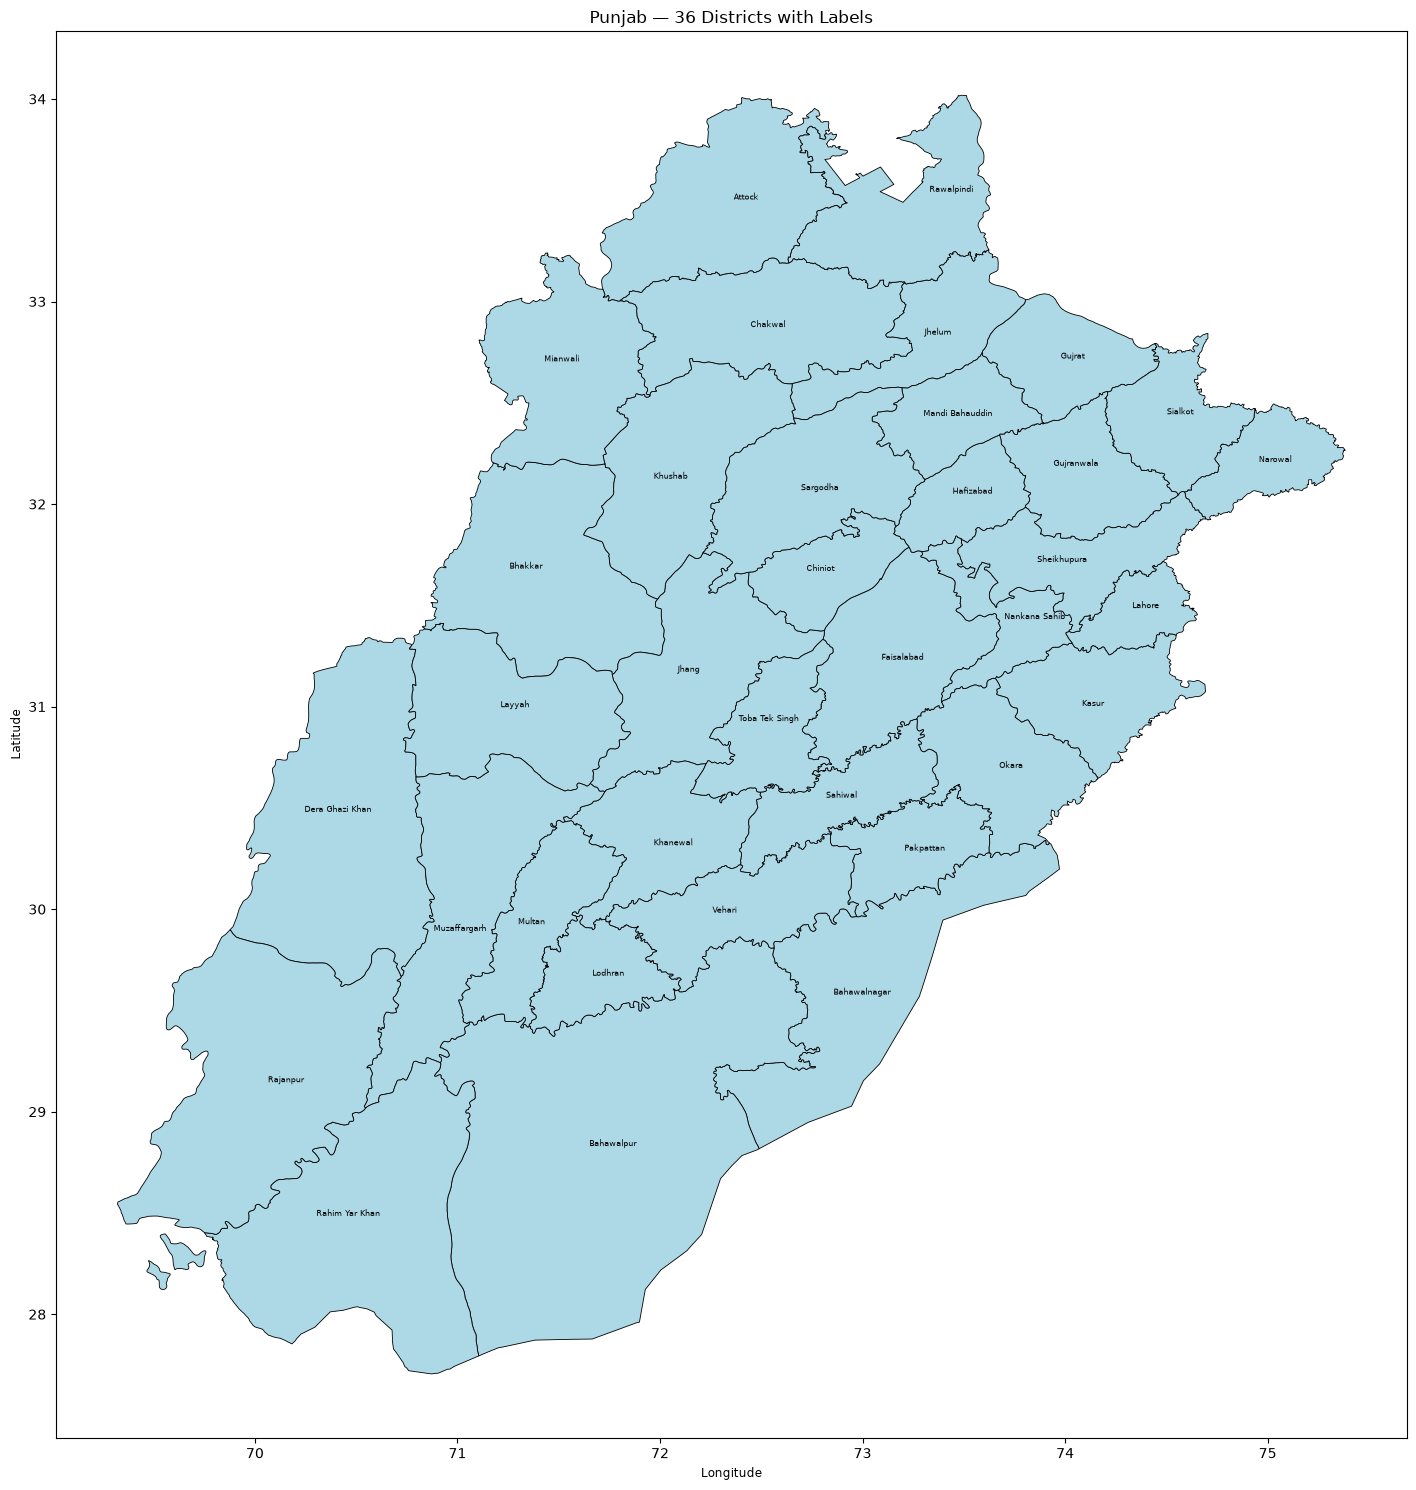

In [32]:
# Purpose: Display district names on the Punjab boundary map.

fig, ax = plt.subplots(figsize=(15, 15))

punjab_districts.plot(
    ax=ax,
    facecolor="lightblue",
    edgecolor="black",
    linewidth=0.6
)

for _, district in punjab_districts.iterrows():
    point = district.geometry.representative_point()

    ax.annotate(
        district["adm2_name"],
        xy=(point.x, point.y),
        ha="center",
        fontsize=6
    )

ax.set_title("Punjab — 36 Districts with Labels")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [33]:
# Purpose: Check the combined geometry of all 36 Punjab districts.

punjab_union = punjab_districts.geometry.union_all()

print("Combined geometry:", punjab_union.geom_type)
print("Geometry valid:", punjab_union.is_valid)
print("Individual area (km²):",
      round(punjab_projected.geometry.area.sum() / 1_000_000, 2))

punjab_union_projected = gpd.GeoSeries(
    [punjab_union], crs=punjab_districts.crs
).to_crs(epsg=32643)

print("Union area (km²):",
      round(punjab_union_projected.area.iloc[0] / 1_000_000, 2))

Combined geometry: MultiPolygon
Geometry valid: True
Individual area (km²): 205549.55
Union area (km²): 205549.55


In [34]:
# Purpose: Count and inspect disconnected parts of the combined Punjab geometry.

print("Geometry type:", punjab_union.geom_type)

if punjab_union.geom_type == "MultiPolygon":
    print("Disconnected polygon parts:", len(punjab_union.geoms))
    print(
        "Area of largest part (km²):",
        round(
            max(
                gpd.GeoSeries(
                    list(punjab_union.geoms),
                    crs=punjab_districts.crs
                ).to_crs(epsg=32643).area
            ) / 1_000_000,
            2
        )
    )

Geometry type: MultiPolygon
Disconnected polygon parts: 3
Area of largest part (km²): 205294.49


   component_id       area_km2
2             3  205294.488339
1             2     183.609427
0             1      71.453632


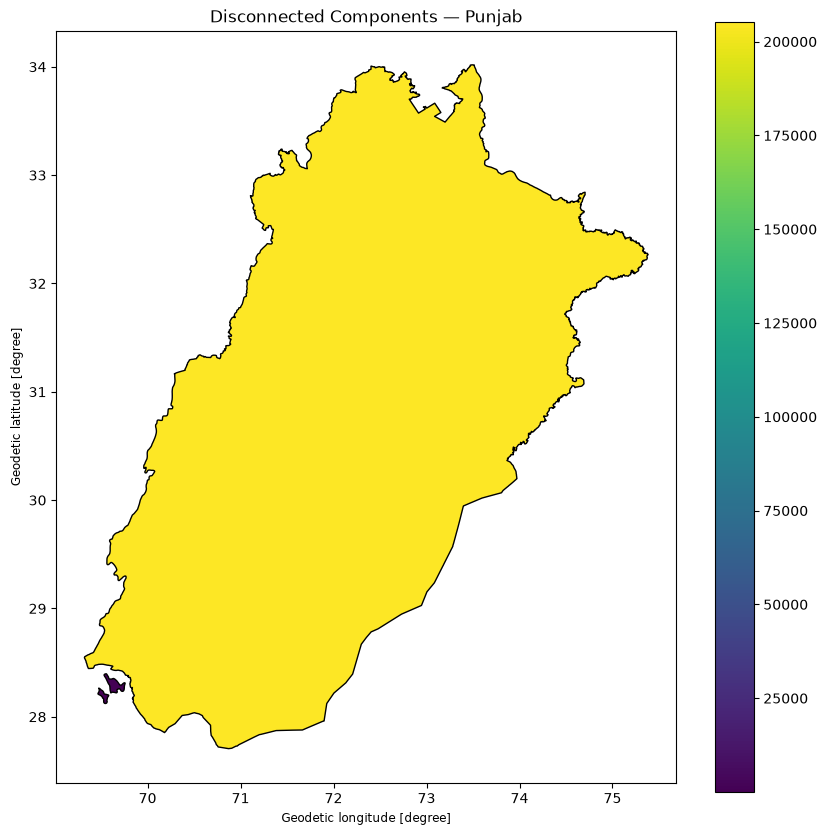

In [35]:
# Purpose: Identify the location and area of each disconnected polygon component.

components = gpd.GeoDataFrame(
    {
        "component_id": range(1, len(punjab_union.geoms) + 1),
        "geometry": list(punjab_union.geoms)
    },
    crs=punjab_districts.crs
).to_crs(epsg=32643)

components["area_km2"] = components.geometry.area / 1_000_000

print(
    components[["component_id", "area_km2"]]
    .sort_values("area_km2", ascending=False)
)

components = components.to_crs(epsg=4326)

components.plot(
    column="area_km2",
    legend=True,
    figsize=(10, 10),
    edgecolor="black"
)

plt.title("Disconnected Components — Punjab")
plt.show()

In [36]:
# Purpose: Inventory the raw and processed data currently available for Punjab.

from pathlib import Path

for folder in [
    Path("../data/raw"),
    Path("../data/processed")
]:
    print(f"\n{folder.resolve()}")

    for file in sorted(folder.iterdir()):
        print(f"  {file.name}")


D:\SoilSenseAI\data\raw
  .gitkeep
  gadm41_PAK_2.json
  out.tif
  pak_admin_boundaries.geojson
  pakistan_districts.geojson
  sahiwal_cec_0-5cm_mean.tif
  sahiwal_clay_0-5cm_mean.tif
  sahiwal_nitrogen_0-5cm_mean.tif
  sahiwal_ph_0-5cm_mean.tif
  sahiwal_phh2o_0-5cm_mean.tif
  sahiwal_phh2o_0-5cm_Q0.5.tif
  sahiwal_phh2o_0-5cm_uncertainty.tif
  sahiwal_sand_0-5cm_mean.tif
  sahiwal_silt_0-5cm_mean.tif
  sahiwal_soc_0-5cm_mean.tif
  website_ph_uncertainty.tif

D:\SoilSenseAI\data\processed
  .gitkeep
  cec_clipped.tif
  clay_clipped.tif
  nitrogen_clipped.tif
  phh2o_clipped.tif
  punjab_districts.geojson
  sahiwal_boundary.geojson
  sahiwal_soil_dataset.csv
  sahiwal_soil_dataset_clean.csv
  sahiwal_soil_dataset_engineered.csv
  sahiwal_soil_dataset_scaled.csv
  sand_clipped.tif
  silt_clipped.tif
  soc_clipped.tif


In [37]:
# Purpose: Calculate Punjab's bounding box in the SoilGrids coordinate system.

import geopandas as gpd

punjab_boundary = gpd.read_file(
    r"D:\SoilSenseAI\data\processed\punjab_districts.geojson"
)

punjab_boundary = punjab_boundary.to_crs("ESRI:54042")

min_x, min_y, max_x, max_y = punjab_boundary.total_bounds

print("CRS:", punjab_boundary.crs)
print("Punjab download extent:")
print("Min X:", round(min_x, 2))
print("Min Y:", round(min_y, 2))
print("Max X:", round(max_x, 2))
print("Max Y:", round(max_y, 2))

CRS: ESRI:54042
Punjab download extent:
Min X: 5970612.51
Min Y: 3179937.87
Max X: 6388226.8
Max Y: 3908706.35


In [38]:
# Purpose: Connect to the SoilGrids pH service and inspect its available coverages.

from owslib.wcs import WebCoverageService

wcs = WebCoverageService(
    "https://maps.isric.org/mapserv?map=/map/phh2o.map",
    version="2.0.1"
)

print("Connection successful")
print("Available coverages:")

for coverage_id in wcs.contents:
    if "0-5cm_mean" in coverage_id:
        print(coverage_id)

coverage = wcs.contents["phh2o_0-5cm_mean"]

print("\nSupported formats:")
print(coverage.supportedFormats)

print("\nSupported CRS:")
print(coverage.supportedCRS)

Connection successful
Available coverages:
phh2o_0-5cm_mean

Supported formats:
['image/tiff', 'image/png', 'image/jpeg', 'image/png; mode=8bit', 'image/vnd.jpeg-png', 'image/vnd.jpeg-png8']

Supported CRS:
[]


In [39]:
# Purpose: Transform Punjab's boundary into the CRS required by SoilGrids WCS.

punjab_soilgrids = punjab_boundary.to_crs(
    "ESRI:54009"
)

min_x, min_y, max_x, max_y = punjab_soilgrids.total_bounds

print("SoilGrids-compatible extent:")
print("West:", round(min_x, 2))
print("South:", round(min_y, 2))
print("East:", round(max_x, 2))
print("North:", round(max_y, 2))

SoilGrids-compatible extent:
West: 6395057.14
South: 3374140.36
East: 6809964.41
North: 4110442.58


In [40]:
# Purpose: Inspect the CRS and spatial limits advertised by the SoilGrids WCS service.

from owslib.wcs import WebCoverageService

print("Coverage bounding boxes:")
for bbox in coverage.boundingboxes:
    print(bbox)

print("\nNative bounding box:")
print(coverage.boundingBox)

print("\nNative CRS:")
print(coverage.boundingBoxWGS84)

Coverage bounding boxes:
{'nativeSrs': 'http://www.opengis.net/def/crs/EPSG/0/152160', 'bbox': (-19949750.0, -6147500.0, 19861750.0, 8361000.0)}

Native bounding box:
None

Native CRS:
None


In [46]:
# Purpose: Transform Punjab into SoilGrids' native Homolosine projection.

punjab_native = punjab_boundary.to_crs("ESRI:54052")

min_x, min_y, max_x, max_y = punjab_native.total_bounds

print("Punjab extent:")
print("West:", round(min_x, 2))
print("South:", round(min_y, 2))
print("East:", round(max_x, 2))
print("North:", round(max_y, 2))


Punjab extent:
West: 7170721.47
South: 3084176.18
East: 7612185.95
North: 3786897.61


In [49]:
# Purpose: Retry the SoilGrids pH test download with the correct coverage identifier.

response = wcs.getCoverage(
    identifier="phh2o_0-5cm_mean",
    subsets=[
        ("X", 7300000, 7350000),
        ("Y", 3300000, 3350000)
    ],
    format="image/tiff",
    crs="http://www.opengis.net/def/crs/EPSG/0/152160",
    response_crs="http://www.opengis.net/def/crs/EPSG/0/152160"
)

test_path = r"D:\SoilSenseAI\data\raw\punjab_ph_test.tif"

with open(test_path, "wb") as file:
    file.write(response.read())

print("Test raster saved:", test_path)

Test raster saved: D:\SoilSenseAI\data\raw\punjab_ph_test.tif


In [50]:
# Purpose: Verify the downloaded pH raster's dimensions, CRS, and pixel values.

import rasterio
import numpy as np

with rasterio.open(test_path) as src:
    data = src.read(1, masked=True)

    print("CRS:", src.crs)
    print("Dimensions:", src.width, "x", src.height)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("Valid pixels:", np.ma.count(data))
    print("Minimum:", data.min())
    print("Maximum:", data.max())
    print("Mean:", data.mean())

CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Interrupted_Goode_Homolosine"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Dimensions: 200 x 200
Resolution: (250.0, 250.0)
Bounds: BoundingBox(left=7300000.0, bottom=3300000.0, right=7350000.0, top=3350000.0)
Valid pixels: 40000
Minimum: 0
Maximum: 83
Mean: 76.2422


In [51]:
# Purpose: Check whether zero values in the test raster represent missing data.

with rasterio.open(test_path) as src:
    data = src.read(1)

    print("NoData metadata:", src.nodata)
    print("Zero-value pixels:", np.count_nonzero(data == 0))
    print("Non-zero pixels:", np.count_nonzero(data != 0))
    print("Unique values:", len(np.unique(data)))
    print("Data type:", data.dtype)

NoData metadata: None
Zero-value pixels: 1133
Non-zero pixels: 38867
Unique values: 11
Data type: int16


In [52]:
# Purpose: Confirm that all seven required Punjab soil-property coverages exist.

properties = {
    "ph": "phh2o",
    "soc": "soc",
    "nitrogen": "nitrogen",
    "clay": "clay",
    "sand": "sand",
    "silt": "silt",
    "cec": "cec"
}

for name, layer in properties.items():
    service = WebCoverageService(
        f"https://maps.isric.org/mapserv?map=/map/{layer}.map",
        version="2.0.1"
    )

    coverage_id = f"{layer}_0-5cm_mean"

    print(
        name,
        "->",
        coverage_id,
        "->",
        "AVAILABLE" if coverage_id in service.contents else "NOT FOUND"
    )

ph -> phh2o_0-5cm_mean -> AVAILABLE
soc -> soc_0-5cm_mean -> AVAILABLE
nitrogen -> nitrogen_0-5cm_mean -> AVAILABLE
clay -> clay_0-5cm_mean -> AVAILABLE
sand -> sand_0-5cm_mean -> AVAILABLE
silt -> silt_0-5cm_mean -> AVAILABLE
cec -> cec_0-5cm_mean -> AVAILABLE


In [53]:
# Purpose: Download all seven 0–5 cm mean SoilGrids rasters for Punjab.

from pathlib import Path
from owslib.wcs import WebCoverageService
import rasterio

raw_dir = Path(r"D:\SoilSenseAI\data\raw")
raw_dir.mkdir(parents=True, exist_ok=True)

crs_uri = "http://www.opengis.net/def/crs/EPSG/0/152160"

min_x, min_y, max_x, max_y = punjab_native.total_bounds

for name, layer in properties.items():

    print(f"\nDownloading {name}...")

    service = WebCoverageService(
        f"https://maps.isric.org/mapserv?map=/map/{layer}.map",
        version="2.0.1"
    )

    coverage_id = f"{layer}_0-5cm_mean"

    response = service.getCoverage(
        identifier=coverage_id,
        subsets=[
            ("X", float(min_x), float(max_x)),
            ("Y", float(min_y), float(max_y))
        ],
        format="image/tiff",
        crs=crs_uri,
        response_crs=crs_uri,
        timeout=300
    )

    output_path = raw_dir / f"punjab_{name}_0-5cm_mean.tif"
    content = response.read()

    if not content.startswith((b"II*\x00", b"MM\x00*", b"II+\x00", b"MM\x00+")):
        raise ValueError(f"Invalid TIFF response for {name}")

    output_path.write_bytes(content)

    with rasterio.open(output_path) as src:
        print("Saved:", output_path.name)
        print("Dimensions:", src.width, "x", src.height)
        print("Resolution:", src.res)
        print("File size (MB):", round(output_path.stat().st_size / 1_000_000, 2))

print("\nAll seven downloads completed.")


Saved: punjab_ph_0-5cm_mean.tif
Dimensions: 1766 x 2811
Resolution: (249.97988942431934, 249.98983709085235)
File size (MB): 1.47

Saved: punjab_soc_0-5cm_mean.tif
Dimensions: 1766 x 2811
Resolution: (249.97988942431934, 249.98983709085235)
File size (MB): 4.35

Saved: punjab_nitrogen_0-5cm_mean.tif
Dimensions: 1766 x 2811
Resolution: (249.97988942431934, 249.98983709085235)
File size (MB): 4.18

Saved: punjab_clay_0-5cm_mean.tif
Dimensions: 1766 x 2811
Resolution: (249.97988942431934, 249.98983709085235)
File size (MB): 4.01

Saved: punjab_sand_0-5cm_mean.tif
Dimensions: 1766 x 2811
Resolution: (249.97988942431934, 249.98983709085235)
File size (MB): 4.15

Saved: punjab_silt_0-5cm_mean.tif
Dimensions: 1766 x 2811
Resolution: (249.97988942431934, 249.98983709085235)
File size (MB): 4.28

Saved: punjab_cec_0-5cm_mean.tif
Dimensions: 1766 x 2811
Resolution: (249.97988942431934, 249.98983709085235)
File size (MB): 3.72

All seven downloads completed.


In [54]:
# Purpose: Clip all SoilGrids rasters to the exact Punjab district boundary.

from rasterio.mask import mask
from rasterio.enums import Resampling
from pathlib import Path
import rasterio

processed_dir = Path(r"D:\SoilSenseAI\data\processed")
processed_dir.mkdir(parents=True, exist_ok=True)

boundary = punjab_districts.to_crs("ESRI:54052")
shapes = [geometry.__geo_interface__ for geometry in boundary.geometry]

for name in properties:

    input_path = raw_dir / f"punjab_{name}_0-5cm_mean.tif"
    output_path = processed_dir / f"punjab_{name}_clipped.tif"

    with rasterio.open(input_path) as src:
        clipped, transform = mask(
            src,
            shapes,
            crop=True,
            filled=True,
            nodata=0
        )

        metadata = src.meta.copy()
        metadata.update({
            "height": clipped.shape[1],
            "width": clipped.shape[2],
            "transform": transform,
            "nodata": 0
        })

        with rasterio.open(output_path, "w", **metadata) as dst:
            dst.write(clipped)

    print(f"{name}: saved -> {output_path.name}")

ph: saved -> punjab_ph_clipped.tif
soc: saved -> punjab_soc_clipped.tif
nitrogen: saved -> punjab_nitrogen_clipped.tif
clay: saved -> punjab_clay_clipped.tif
sand: saved -> punjab_sand_clipped.tif
silt: saved -> punjab_silt_clipped.tif
cec: saved -> punjab_cec_clipped.tif


In [55]:
# Purpose: Verify raster alignment, dimensions, CRS, and valid pixel counts.

import numpy as np
import rasterio

reference = None

for name in properties:
    path = processed_dir / f"punjab_{name}_clipped.tif"

    with rasterio.open(path) as src:
        data = src.read(1)

        grid = (
            src.crs,
            src.width,
            src.height,
            src.transform
        )

        aligned = reference is None or grid == reference

        if reference is None:
            reference = grid

        valid_pixels = np.count_nonzero(data != 0)
        missing_pixels = np.count_nonzero(data == 0)

        print(f"\n{name.upper()}")
        print("Dimensions:", src.width, "x", src.height)
        print("CRS:", src.crs)
        print("Aligned:", aligned)
        print("Valid pixels:", valid_pixels)
        print("Missing pixels:", missing_pixels)
        print("Min / Max:", data[data != 0].min(), "/", data.max())


PH
Dimensions: 1766 x 2811
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Interrupted_Goode_Homolosine"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Aligned: True
Valid pixels: 3223093
Missing pixels: 1741133
Min / Max: 56 / 101

SOC
Dimensions: 1766 x 2811
CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Interrupted_Goode_Homolosine"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Aligned: True

In [56]:
# Purpose: Combine the seven aligned SoilGrids rasters into one province-wide dataset.

import numpy as np
import pandas as pd
import rasterio

data_arrays = {}
pixel_centers = None

for name in properties:
    path = processed_dir / f"punjab_{name}_clipped.tif"

    with rasterio.open(path) as src:
        data = src.read(1)
        valid_mask = data != 0

        if pixel_centers is None:
            rows, cols = np.where(valid_mask)

            xs, ys = rasterio.transform.xy(
                src.transform, rows, cols, offset="center"
            )

            pixel_centers = {
                "x": np.array(xs),
                "y": np.array(ys)
            }

        data_arrays[name] = data[valid_mask]

soil_df = pd.DataFrame({
    "x": pixel_centers["x"],
    "y": pixel_centers["y"],
    **data_arrays
})

print("Dataset shape:", soil_df.shape)
print("\nColumns:", soil_df.columns.tolist())
print("\nMissing values:\n", soil_df.isna().sum())
print("\nFirst five rows:")
display(soil_df.head())

Dataset shape: (3223093, 9)

Columns: ['x', 'y', 'ph', 'soc', 'nitrogen', 'clay', 'sand', 'silt', 'cec']

Missing values:
 x           0
y           0
ph          0
soc         0
nitrogen    0
clay        0
sand        0
silt        0
cec         0
dtype: int64

First five rows:


,x,y,ph,soc,nitrogen,clay,sand,silt,cec
0,7.351832e+06,3.786773e+06,66,412,332,287,279,434,207
1,7.352082e+06,3.786773e+06,68,385,351,285,278,437,216
2,7.352332e+06,3.786773e+06,69,435,337,291,274,434,218
3,7.352582e+06,3.786773e+06,68,411,336,288,278,435,215
4,7.352832e+06,3.786773e+06,68,438,354,292,272,436,223


In [57]:
# Purpose: Convert SoilGrids raster coordinates into WGS84 longitude and latitude.

from pyproj import Transformer
import rasterio

with rasterio.open(processed_dir / "punjab_ph_clipped.tif") as src:
    raster_crs = src.crs

transformer = Transformer.from_crs(
    raster_crs,
    "EPSG:4326",
    always_xy=True
)

soil_df["longitude"], soil_df["latitude"] = transformer.transform(
    soil_df["x"].to_numpy(),
    soil_df["y"].to_numpy()
)

print("Coordinate conversion complete.")

print("\nLongitude range:")
print(soil_df["longitude"].min(), soil_df["longitude"].max())

print("\nLatitude range:")
print(soil_df["latitude"].min(), soil_df["latitude"].max())

display(soil_df[["longitude", "latitude"]].head())

Coordinate conversion complete.

Longitude range:
69.32230210665652 75.38118229055452

Latitude range:
27.70674884845783 34.01715718054249


,longitude,latitude
0,73.484052,34.017157
1,73.486761,34.017157
2,73.489470,34.017157
3,73.492179,34.017157
4,73.494889,34.017157


In [58]:
# Purpose: Verify that all extracted soil pixels fall within Punjab's geographic extent.

print("Longitude:")
print("Minimum:", soil_df["longitude"].min())
print("Maximum:", soil_df["longitude"].max())

print("\nLatitude:")
print("Minimum:", soil_df["latitude"].min())
print("Maximum:", soil_df["latitude"].max())

print("\nCoordinate summary:")
display(soil_df[["longitude", "latitude"]].describe())

Longitude:
Minimum: 69.32230210665652
Maximum: 75.38118229055452

Latitude:
Minimum: 27.70674884845783
Maximum: 34.01715718054249

Coordinate summary:


,longitude,latitude
count,3.223093e+06,3.223093e+06
mean,7.212320e+01,3.077947e+01
std,1.253449e+00,1.529930e+00
min,6.932230e+01,2.770675e+01
25%,7.118732e+01,2.953025e+01
50%,7.209515e+01,3.079009e+01
75%,7.305283e+01,3.204544e+01
max,7.538118e+01,3.401716e+01


In [59]:
# Purpose: Check whether sampled soil pixel centres fall inside Punjab's boundary.

import numpy as np
import geopandas as gpd
from shapely import contains_xy

boundary_wgs84 = punjab_districts.to_crs("EPSG:4326")
punjab_geometry = boundary_wgs84.geometry.union_all()

sample = soil_df.sample(n=10000, random_state=42)

inside = contains_xy(
    punjab_geometry,
    sample["longitude"].to_numpy(),
    sample["latitude"].to_numpy()
)

print("Sampled pixels:", len(sample))
print("Inside Punjab:", int(inside.sum()))
print("Outside Punjab:", int((~inside).sum()))
print("Inside percentage:", round(inside.mean() * 100, 2), "%")

Sampled pixels: 10000
Inside Punjab: 10000
Outside Punjab: 0
Inside percentage: 100.0 %


In [60]:
# Purpose: Save the complete Punjab SoilGrids dataset as a CSV file.

output_path = processed_dir / "punjab_soil_dataset.csv"

final_columns = [
    "longitude", "latitude",
    "ph", "soc", "nitrogen",
    "clay", "sand", "silt", "cec"
]

soil_df[final_columns].to_csv(output_path, index=False)

print("Dataset saved successfully.")
print("Path:", output_path)
print("Records:", len(soil_df))
print("Columns:", len(final_columns))
print("File size (MB):", round(output_path.stat().st_size / 1_000_000, 2))

Dataset saved successfully.
Path: D:\SoilSenseAI\data\processed\punjab_soil_dataset.csv
Records: 3223093
Columns: 9
File size (MB): 204.16


In [61]:
# Purpose: Verify the saved Punjab dataset and inspect its contents.

import pandas as pd

saved_df = pd.read_csv(output_path)

print("Dataset shape:", saved_df.shape)
print("\nMissing values:")
print(saved_df.isnull().sum())

print("\nFirst five records:")
display(saved_df.head())

print("\nProperty statistics:")
display(saved_df.describe().round(3))

Dataset shape: (3223093, 9)

Missing values:
longitude    0
latitude     0
ph           0
soc          0
nitrogen     0
clay         0
sand         0
silt         0
cec          0
dtype: int64

First five records:


,longitude,latitude,ph,soc,nitrogen,clay,sand,silt,cec
0,73.484052,34.017157,66,412,332,287,279,434,207
1,73.486761,34.017157,68,385,351,285,278,437,216
2,73.489470,34.017157,69,435,337,291,274,434,218
3,73.492179,34.017157,68,411,336,288,278,435,215
4,73.494889,34.017157,68,438,354,292,272,436,223



Property statistics:


,longitude,latitude,ph,soc,nitrogen,clay,sand,silt,cec
count,3223093.000,3223093.000,3223093.000,3223093.000,3223093.000,3223093.000,3223093.000,3223093.000,3223093.000
mean,72.123,30.779,78.848,100.928,113.358,224.543,408.323,367.133,161.198
std,1.253,1.530,2.632,52.032,48.431,27.159,89.796,88.678,23.488
min,69.322,27.707,56.000,26.000,28.000,106.000,53.000,130.000,74.000
25%,71.187,29.530,78.000,69.000,86.000,209.000,341.000,300.000,143.000
50%,72.095,30.790,79.000,93.000,105.000,224.000,418.000,358.000,160.000
75%,73.053,32.045,80.000,117.000,129.000,239.000,479.000,427.000,179.000
max,75.381,34.017,101.000,992.000,654.000,400.000,669.000,818.000,266.000


In [63]:
# Purpose: List available SoilGrids coverage identifiers.

coverage_ids = sorted(wcs.contents.keys())

print("Total available coverages:", len(coverage_ids))
print("\nAvailable coverage IDs:")

for coverage_id in coverage_ids:
    print(coverage_id)

Total available coverages: 30

Available coverage IDs:
phh2o_0-5cm_Q0.05
phh2o_0-5cm_Q0.5
phh2o_0-5cm_Q0.95
phh2o_0-5cm_mean
phh2o_0-5cm_uncertainty
phh2o_100-200cm_Q0.05
phh2o_100-200cm_Q0.5
phh2o_100-200cm_Q0.95
phh2o_100-200cm_mean
phh2o_100-200cm_uncertainty
phh2o_15-30cm_Q0.05
phh2o_15-30cm_Q0.5
phh2o_15-30cm_Q0.95
phh2o_15-30cm_mean
phh2o_15-30cm_uncertainty
phh2o_30-60cm_Q0.05
phh2o_30-60cm_Q0.5
phh2o_30-60cm_Q0.95
phh2o_30-60cm_mean
phh2o_30-60cm_uncertainty
phh2o_5-15cm_Q0.05
phh2o_5-15cm_Q0.5
phh2o_5-15cm_Q0.95
phh2o_5-15cm_mean
phh2o_5-15cm_uncertainty
phh2o_60-100cm_Q0.05
phh2o_60-100cm_Q0.5
phh2o_60-100cm_Q0.95
phh2o_60-100cm_mean
phh2o_60-100cm_uncertainty


In [64]:
# Purpose: Inspect the connected SoilGrids WCS service configuration.

print("WCS URL:", wcs.url)
print("WCS version:", wcs.version)

print("\nCoverage count:", len(wcs.contents))
print("First coverage:", coverage_ids[0])

WCS URL: https://maps.isric.org/mapserv?map=/map/phh2o.map
WCS version: 2.0.1

Coverage count: 30
First coverage: phh2o_0-5cm_Q0.05


In [65]:
# Purpose: Connect to all documented SoilGrids numeric property services and list their coverages.

from owslib.wcs import WebCoverageService

property_codes = [
    "phh2o", "soc", "nitrogen", "clay", "sand", "silt", "cec",
    "bdod", "cfvo", "ocd", "ocs", "wv0010", "wv003", "wv1500"
]

wcs_services = {"phh2o": wcs}
coverage_inventory = {}

for code in property_codes:
    if code not in wcs_services:
        url = f"https://maps.isric.org/mapserv?map=/map/{code}.map"

        try:
            wcs_services[code] = WebCoverageService(
                url,
                version="2.0.1"
            )
        except Exception as error:
            print(f"\n{code}: CONNECTION FAILED - {error}")
            continue

    ids = sorted(wcs_services[code].contents.keys())
    coverage_inventory[code] = ids

    print(f"\n{code}: {len(ids)} coverages")
    print(", ".join(ids))


phh2o: 30 coverages
phh2o_0-5cm_Q0.05, phh2o_0-5cm_Q0.5, phh2o_0-5cm_Q0.95, phh2o_0-5cm_mean, phh2o_0-5cm_uncertainty, phh2o_100-200cm_Q0.05, phh2o_100-200cm_Q0.5, phh2o_100-200cm_Q0.95, phh2o_100-200cm_mean, phh2o_100-200cm_uncertainty, phh2o_15-30cm_Q0.05, phh2o_15-30cm_Q0.5, phh2o_15-30cm_Q0.95, phh2o_15-30cm_mean, phh2o_15-30cm_uncertainty, phh2o_30-60cm_Q0.05, phh2o_30-60cm_Q0.5, phh2o_30-60cm_Q0.95, phh2o_30-60cm_mean, phh2o_30-60cm_uncertainty, phh2o_5-15cm_Q0.05, phh2o_5-15cm_Q0.5, phh2o_5-15cm_Q0.95, phh2o_5-15cm_mean, phh2o_5-15cm_uncertainty, phh2o_60-100cm_Q0.05, phh2o_60-100cm_Q0.5, phh2o_60-100cm_Q0.95, phh2o_60-100cm_mean, phh2o_60-100cm_uncertainty

soc: 30 coverages
soc_0-5cm_Q0.05, soc_0-5cm_Q0.5, soc_0-5cm_Q0.95, soc_0-5cm_mean, soc_0-5cm_uncertainty, soc_100-200cm_Q0.05, soc_100-200cm_Q0.5, soc_100-200cm_Q0.95, soc_100-200cm_mean, soc_100-200cm_uncertainty, soc_15-30cm_Q0.05, soc_15-30cm_Q0.5, soc_15-30cm_Q0.95, soc_15-30cm_mean, soc_15-30cm_uncertainty, soc_30-60c

In [66]:
# Purpose: Check the SoilGrids water-content service at 33 kPa.

url = "https://maps.isric.org/mapserv?map=/map/wv0033.map"

try:
    wcs_services["wv0033"] = WebCoverageService(
        url,
        version="2.0.1"
    )

    wv0033_ids = sorted(wcs_services["wv0033"].contents.keys())

    print("Connection successful.")
    print("Available coverages:", len(wv0033_ids))

    for coverage_id in wv0033_ids:
        print(coverage_id)

except Exception as error:
    print("Connection failed:", error)

Connection successful.
Available coverages: 30
wv0033_0-5cm_Q0.05
wv0033_0-5cm_Q0.5
wv0033_0-5cm_Q0.95
wv0033_0-5cm_mean
wv0033_0-5cm_uncertainty
wv0033_100-200cm_Q0.05
wv0033_100-200cm_Q0.5
wv0033_100-200cm_Q0.95
wv0033_100-200cm_mean
wv0033_100-200cm_uncertainty
wv0033_15-30cm_Q0.05
wv0033_15-30cm_Q0.5
wv0033_15-30cm_Q0.95
wv0033_15-30cm_mean
wv0033_15-30cm_uncertainty
wv0033_30-60cm_Q0.05
wv0033_30-60cm_Q0.5
wv0033_30-60cm_Q0.95
wv0033_30-60cm_mean
wv0033_30-60cm_uncertainty
wv0033_5-15cm_Q0.05
wv0033_5-15cm_Q0.5
wv0033_5-15cm_Q0.95
wv0033_5-15cm_mean
wv0033_5-15cm_uncertainty
wv0033_60-100cm_Q0.05
wv0033_60-100cm_Q0.5
wv0033_60-100cm_Q0.95
wv0033_60-100cm_mean
wv0033_60-100cm_uncertainty


In [67]:
# Purpose: Build a download plan for all available SoilGrids mean layers.

depths = [
    "0-5cm",
    "5-15cm",
    "15-30cm",
    "30-60cm",
    "60-100cm",
    "100-200cm"
]

download_plan = []

for code in property_codes:
    if code == "wv003":
        continue

    service = wcs_services.get(code)

    if service is None:
        continue

    available = set(service.contents.keys())

    property_depths = ["0-30cm"] if code == "ocs" else depths

    for depth in property_depths:
        coverage_id = f"{code}_{depth}_mean"

        if coverage_id not in available:
            continue

        filename = f"punjab_{code}_{depth}_mean.tif"

        # The original seven topsoil rasters already exist.
        if depth == "0-5cm" and code in properties:
            continue

        download_plan.append({
            "property": code,
            "depth": depth,
            "coverage": coverage_id,
            "filename": filename
        })

print("Additional rasters to download:", len(download_plan))

for code in sorted(set(item["property"] for item in download_plan)):
    items = [item for item in download_plan if item["property"] == code]
    print(f"{code}: {len(items)} layers")

Additional rasters to download: 67
bdod: 6 layers
cec: 5 layers
cfvo: 6 layers
clay: 5 layers
nitrogen: 5 layers
ocd: 6 layers
ocs: 1 layers
phh2o: 6 layers
sand: 5 layers
silt: 5 layers
soc: 5 layers
wv0010: 6 layers
wv1500: 6 layers


In [68]:
# Purpose: Correct the property list and include all available 33 kPa water-retention layers.

property_codes = [
    "phh2o", "soc", "nitrogen", "clay", "sand", "silt", "cec",
    "bdod", "cfvo", "ocd", "ocs", "wv0010", "wv0033", "wv1500"
]

download_plan = []

for code in property_codes:
    service = wcs_services.get(code)

    if service is None:
        continue

    available = set(service.contents.keys())
    property_depths = ["0-30cm"] if code == "ocs" else depths

    for depth in property_depths:
        coverage_id = f"{code}_{depth}_mean"

        if coverage_id not in available:
            continue

        if depth == "0-5cm" and code in properties:
            continue

        download_plan.append({
            "property": code,
            "depth": depth,
            "coverage": coverage_id,
            "filename": f"punjab_{code}_{depth}_mean.tif"
        })

print("Corrected additional raster count:", len(download_plan))

for code in property_codes:
    count = sum(item["property"] == code for item in download_plan)
    print(f"{code}: {count} additional layers")

Corrected additional raster count: 73
phh2o: 6 additional layers
soc: 5 additional layers
nitrogen: 5 additional layers
clay: 5 additional layers
sand: 5 additional layers
silt: 5 additional layers
cec: 5 additional layers
bdod: 6 additional layers
cfvo: 6 additional layers
ocd: 6 additional layers
ocs: 1 additional layers
wv0010: 6 additional layers
wv0033: 6 additional layers
wv1500: 6 additional layers


In [70]:
# Purpose: Test a Punjab pH raster download using standard Python float coordinates.

bounds = [float(value) for value in punjab_native.total_bounds]

min_x, min_y, max_x, max_y = bounds

print("Bounds:", bounds)

test_response = wcs_services["phh2o"].getCoverage(
    identifier="phh2o_5-15cm_mean",
    subsets=[
        ("X", min_x, max_x),
        ("Y", min_y, max_y)
    ],
    format="image/tiff",
    crs="http://www.opengis.net/def/crs/EPSG/0/152160",
    response_crs="http://www.opengis.net/def/crs/EPSG/0/152160"
)

test_path = raw_dir / "punjab_phh2o_5-15cm_mean.tif"

with open(test_path, "wb") as file:
    file.write(test_response.read())

print("Test download successful:", test_path)

Bounds: [7170721.465692938, 3084176.1784288995, 7612185.9504162865, 3786897.610491285]
Test download successful: D:\SoilSenseAI\data\raw\punjab_phh2o_5-15cm_mean.tif


In [71]:
# Purpose: Download the first 10 planned rasters, skipping existing files and tracking failures.

batch = download_plan[:10]
failed_downloads = []

for item in batch:
    output_file = raw_dir / item["filename"]

    if output_file.exists():
        print("Already exists:", item["filename"])
        continue

    try:
        response = wcs_services[item["property"]].getCoverage(
            identifier=item["coverage"],
            subsets=[
                ("X", float(min_x), float(max_x)),
                ("Y", float(min_y), float(max_y))
            ],
            format="image/tiff",
            crs="http://www.opengis.net/def/crs/EPSG/0/152160",
            response_crs="http://www.opengis.net/def/crs/EPSG/0/152160"
        )

        with open(output_file, "wb") as file:
            file.write(response.read())

        print("Downloaded:", item["filename"])

    except Exception as error:
        failed_downloads.append(item)
        print("FAILED:", item["filename"], "-", error)

print("\nBatch complete.")
print("Failed downloads:", len(failed_downloads))

Downloaded: punjab_phh2o_0-5cm_mean.tif
Already exists: punjab_phh2o_5-15cm_mean.tif
Downloaded: punjab_phh2o_15-30cm_mean.tif
Downloaded: punjab_phh2o_30-60cm_mean.tif
Downloaded: punjab_phh2o_60-100cm_mean.tif
Downloaded: punjab_phh2o_100-200cm_mean.tif
Downloaded: punjab_soc_5-15cm_mean.tif
Downloaded: punjab_soc_15-30cm_mean.tif
Downloaded: punjab_soc_30-60cm_mean.tif
Downloaded: punjab_soc_60-100cm_mean.tif

Batch complete.
Failed downloads: 0


In [72]:
# Purpose: Download the second batch of 10 additional Punjab SoilGrids mean rasters.

batch = download_plan[10:20]
failed_downloads = []

for item in batch:
    output_file = raw_dir / item["filename"]

    if output_file.exists():
        print("Already exists:", item["filename"])
        continue

    try:
        response = wcs_services[item["property"]].getCoverage(
            identifier=item["coverage"],
            subsets=[
                ("X", float(min_x), float(max_x)),
                ("Y", float(min_y), float(max_y))
            ],
            format="image/tiff",
            crs="http://www.opengis.net/def/crs/EPSG/0/152160",
            response_crs="http://www.opengis.net/def/crs/EPSG/0/152160"
        )

        with open(output_file, "wb") as file:
            file.write(response.read())

        print("Downloaded:", item["filename"])

    except Exception as error:
        failed_downloads.append(item)
        print("FAILED:", item["filename"], "-", error)

print("\nBatch complete.")
print("Failed downloads:", len(failed_downloads))

Downloaded: punjab_soc_100-200cm_mean.tif
Downloaded: punjab_nitrogen_5-15cm_mean.tif
Downloaded: punjab_nitrogen_15-30cm_mean.tif
Downloaded: punjab_nitrogen_30-60cm_mean.tif
Downloaded: punjab_nitrogen_60-100cm_mean.tif
Downloaded: punjab_nitrogen_100-200cm_mean.tif
Downloaded: punjab_clay_5-15cm_mean.tif
Downloaded: punjab_clay_15-30cm_mean.tif
Downloaded: punjab_clay_30-60cm_mean.tif
Downloaded: punjab_clay_60-100cm_mean.tif

Batch complete.
Failed downloads: 0


In [73]:
# Purpose: Download the third batch of 10 additional Punjab SoilGrids mean rasters.

batch = download_plan[20:30]
failed_downloads = []

for item in batch:
    output_file = raw_dir / item["filename"]

    if output_file.exists():
        print("Already exists:", item["filename"])
        continue

    try:
        response = wcs_services[item["property"]].getCoverage(
            identifier=item["coverage"],
            subsets=[
                ("X", float(min_x), float(max_x)),
                ("Y", float(min_y), float(max_y))
            ],
            format="image/tiff",
            crs="http://www.opengis.net/def/crs/EPSG/0/152160",
            response_crs="http://www.opengis.net/def/crs/EPSG/0/152160"
        )

        with open(output_file, "wb") as file:
            file.write(response.read())

        print("Downloaded:", item["filename"])

    except Exception as error:
        failed_downloads.append(item)
        print("FAILED:", item["filename"], "-", error)

print("\nBatch complete.")
print("Failed downloads:", len(failed_downloads))

Downloaded: punjab_clay_100-200cm_mean.tif
Downloaded: punjab_sand_5-15cm_mean.tif
Downloaded: punjab_sand_15-30cm_mean.tif
Downloaded: punjab_sand_30-60cm_mean.tif
Downloaded: punjab_sand_60-100cm_mean.tif
Downloaded: punjab_sand_100-200cm_mean.tif
Downloaded: punjab_silt_5-15cm_mean.tif
Downloaded: punjab_silt_15-30cm_mean.tif
Downloaded: punjab_silt_30-60cm_mean.tif
Downloaded: punjab_silt_60-100cm_mean.tif

Batch complete.
Failed downloads: 0


In [74]:
# Purpose: Download all remaining Punjab SoilGrids mean rasters.

failed_downloads = []
downloaded_count = 0
skipped_count = 0

for i, item in enumerate(download_plan[30:], start=31):
    output_file = raw_dir / item["filename"]

    if output_file.exists():
        skipped_count += 1
        print(f"[{i}/73] Already exists: {item['filename']}")
        continue

    try:
        response = wcs_services[item["property"]].getCoverage(
            identifier=item["coverage"],
            subsets=[
                ("X", float(min_x), float(max_x)),
                ("Y", float(min_y), float(max_y))
            ],
            format="image/tiff",
            crs="http://www.opengis.net/def/crs/EPSG/0/152160",
            response_crs="http://www.opengis.net/def/crs/EPSG/0/152160"
        )

        with open(output_file, "wb") as file:
            file.write(response.read())

        downloaded_count += 1
        print(f"[{i}/73] Downloaded: {item['filename']}")

    except Exception as error:
        failed_downloads.append(item)
        print(f"[{i}/73] FAILED: {item['filename']} - {error}")

print("\nDOWNLOAD SUMMARY")
print("Newly downloaded:", downloaded_count)
print("Already existed:", skipped_count)
print("Failed:", len(failed_downloads))
print("Remaining failures:", [
    item["filename"] for item in failed_downloads
])

[31/73] Downloaded: punjab_silt_100-200cm_mean.tif
[32/73] Downloaded: punjab_cec_5-15cm_mean.tif
[33/73] Downloaded: punjab_cec_15-30cm_mean.tif
[34/73] Downloaded: punjab_cec_30-60cm_mean.tif
[35/73] Downloaded: punjab_cec_60-100cm_mean.tif
[36/73] Downloaded: punjab_cec_100-200cm_mean.tif
[37/73] Downloaded: punjab_bdod_0-5cm_mean.tif
[38/73] Downloaded: punjab_bdod_5-15cm_mean.tif
[39/73] Downloaded: punjab_bdod_15-30cm_mean.tif
[40/73] Downloaded: punjab_bdod_30-60cm_mean.tif
[41/73] Downloaded: punjab_bdod_60-100cm_mean.tif
[42/73] Downloaded: punjab_bdod_100-200cm_mean.tif
[43/73] Downloaded: punjab_cfvo_0-5cm_mean.tif
[44/73] Downloaded: punjab_cfvo_5-15cm_mean.tif
[45/73] Downloaded: punjab_cfvo_15-30cm_mean.tif
[46/73] Downloaded: punjab_cfvo_30-60cm_mean.tif
[47/73] Downloaded: punjab_cfvo_60-100cm_mean.tif
[48/73] Downloaded: punjab_cfvo_100-200cm_mean.tif
[49/73] Downloaded: punjab_ocd_0-5cm_mean.tif
[50/73] Downloaded: punjab_ocd_5-15cm_mean.tif
[51/73] Downloaded: punjab

In [75]:
# Purpose: Check whether all downloaded SoilGrids rasters share the same spatial grid.

import rasterio
from collections import Counter

raster_files = sorted(raw_dir.glob("punjab_*.tif"))

metadata = []

for file_path in raster_files:
    with rasterio.open(file_path) as src:
        metadata.append({
            "filename": file_path.name,
            "width": src.width,
            "height": src.height,
            "crs": str(src.crs),
            "resolution": src.res,
            "transform": tuple(src.transform),
            "nodata": src.nodata
        })

print("Total raster files:", len(metadata))
print("\nRaster dimensions:")
print(Counter((m["width"], m["height"]) for m in metadata))

print("\nCRS count:")
print(Counter(m["crs"] for m in metadata))

print("\nResolution count:")
print(Counter(m["resolution"] for m in metadata))

reference_grid = (
    metadata[0]["width"],
    metadata[0]["height"],
    metadata[0]["crs"],
    metadata[0]["transform"]
)

misaligned = [
    m["filename"] for m in metadata
    if (
        m["width"],
        m["height"],
        m["crs"],
        m["transform"]
    ) != reference_grid
]

print("\nRasters not aligned with the first raster:", len(misaligned))
print(misaligned)

Total raster files: 81

Raster dimensions:
Counter({(1766, 2811): 80, (200, 200): 1})

CRS count:
Counter({'PROJCS["unknown",GEOGCS["unknown",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Interrupted_Goode_Homolosine"],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]': 81})

Resolution count:
Counter({(249.97988942431934, 249.98983709085235): 80, (250.0, 250.0): 1})

Rasters not aligned with the first raster: 1
['punjab_ph_test.tif']


In [76]:
# Purpose: Clip all aligned SoilGrids rasters to the Punjab boundary.

import rasterio
from rasterio.mask import mask

punjab_geometry = [
    geometry.__geo_interface__
    for geometry in punjab_native.geometry
]

clipped_count = 0

for file_path in sorted(raw_dir.glob("punjab_*.tif")):

    if file_path.name == "punjab_ph_test.tif":
        continue

    output_file = processed_dir / f"{file_path.stem}_clipped.tif"

    if output_file.exists():
        continue

    with rasterio.open(file_path) as src:
        clipped_image, clipped_transform = mask(
            src,
            punjab_geometry,
            crop=True,
            filled=True,
            nodata=0
        )

        output_meta = src.meta.copy()
        output_meta.update({
            "height": clipped_image.shape[1],
            "width": clipped_image.shape[2],
            "transform": clipped_transform,
            "nodata": 0
        })

        with rasterio.open(output_file, "w", **output_meta) as dst:
            dst.write(clipped_image)

    clipped_count += 1
    print("Clipped:", file_path.name)

print("\nNewly clipped rasters:", clipped_count)
print("Total clipped raster files:", len(list(processed_dir.glob("*_clipped.tif"))))

Clipped: punjab_bdod_0-5cm_mean.tif
Clipped: punjab_bdod_100-200cm_mean.tif
Clipped: punjab_bdod_15-30cm_mean.tif
Clipped: punjab_bdod_30-60cm_mean.tif
Clipped: punjab_bdod_5-15cm_mean.tif
Clipped: punjab_bdod_60-100cm_mean.tif
Clipped: punjab_cec_0-5cm_mean.tif
Clipped: punjab_cec_100-200cm_mean.tif
Clipped: punjab_cec_15-30cm_mean.tif
Clipped: punjab_cec_30-60cm_mean.tif
Clipped: punjab_cec_5-15cm_mean.tif
Clipped: punjab_cec_60-100cm_mean.tif
Clipped: punjab_cfvo_0-5cm_mean.tif
Clipped: punjab_cfvo_100-200cm_mean.tif
Clipped: punjab_cfvo_15-30cm_mean.tif
Clipped: punjab_cfvo_30-60cm_mean.tif
Clipped: punjab_cfvo_5-15cm_mean.tif
Clipped: punjab_cfvo_60-100cm_mean.tif
Clipped: punjab_clay_0-5cm_mean.tif
Clipped: punjab_clay_100-200cm_mean.tif
Clipped: punjab_clay_15-30cm_mean.tif
Clipped: punjab_clay_30-60cm_mean.tif
Clipped: punjab_clay_5-15cm_mean.tif
Clipped: punjab_clay_60-100cm_mean.tif
Clipped: punjab_nitrogen_0-5cm_mean.tif
Clipped: punjab_nitrogen_100-200cm_mean.tif
Clipped: p

In [77]:
# Purpose: Verify spatial alignment and valid-data coverage of all clipped rasters.

import rasterio
import numpy as np

clipped_files = sorted(processed_dir.glob("*_clipped.tif"))

reference = None
misaligned = []
coverage_summary = []

for file_path in clipped_files:
    with rasterio.open(file_path) as src:

        grid = (
            src.width,
            src.height,
            src.crs,
            src.transform
        )

        if reference is None:
            reference = grid
        elif grid != reference:
            misaligned.append(file_path.name)

        data = src.read(1)
        valid_pixels = int(np.count_nonzero(data != 0))

        coverage_summary.append({
            "file": file_path.name,
            "valid_pixels": valid_pixels
        })

print("Total clipped rasters:", len(clipped_files))
print("Rasters with alignment issues:", len(misaligned))
print("Misaligned files:", misaligned)

print("\nReference grid:")
print("Dimensions:", reference[0], "x", reference[1])
print("CRS:", reference[2])
print("Resolution:", reference[3].a, reference[3].e)

print("\nValid pixels in first clipped raster:",
      coverage_summary[0]["valid_pixels"])

Total clipped rasters: 94
Rasters with alignment issues: 87
Misaligned files: ['punjab_bdod_0-5cm_mean_clipped.tif', 'punjab_bdod_100-200cm_mean_clipped.tif', 'punjab_bdod_15-30cm_mean_clipped.tif', 'punjab_bdod_30-60cm_mean_clipped.tif', 'punjab_bdod_5-15cm_mean_clipped.tif', 'punjab_bdod_60-100cm_mean_clipped.tif', 'punjab_cec_0-5cm_mean_clipped.tif', 'punjab_cec_100-200cm_mean_clipped.tif', 'punjab_cec_15-30cm_mean_clipped.tif', 'punjab_cec_30-60cm_mean_clipped.tif', 'punjab_cec_5-15cm_mean_clipped.tif', 'punjab_cec_60-100cm_mean_clipped.tif', 'punjab_cec_clipped.tif', 'punjab_cfvo_0-5cm_mean_clipped.tif', 'punjab_cfvo_100-200cm_mean_clipped.tif', 'punjab_cfvo_15-30cm_mean_clipped.tif', 'punjab_cfvo_30-60cm_mean_clipped.tif', 'punjab_cfvo_5-15cm_mean_clipped.tif', 'punjab_cfvo_60-100cm_mean_clipped.tif', 'punjab_clay_0-5cm_mean_clipped.tif', 'punjab_clay_100-200cm_mean_clipped.tif', 'punjab_clay_15-30cm_mean_clipped.tif', 'punjab_clay_30-60cm_mean_clipped.tif', 'punjab_clay_5-15cm_m

In [78]:
# Purpose: Determine whether clipped rasters preserve their original pixel grids.

import rasterio
import numpy as np
from collections import Counter

diagnostics = []

for clipped_path in sorted(processed_dir.glob("*_clipped.tif")):
    raw_path = raw_dir / clipped_path.name.replace("_clipped", "")

    if not raw_path.exists():
        continue

    with rasterio.open(raw_path) as raw, rasterio.open(clipped_path) as clipped:

        pixel_x = raw.transform.a
        pixel_y = raw.transform.e

        col_offset = (clipped.transform.c - raw.transform.c) / pixel_x
        row_offset = (clipped.transform.f - raw.transform.f) / pixel_y

        diagnostics.append({
            "file": clipped_path.name,
            "same_crs": raw.crs == clipped.crs,
            "same_resolution": np.allclose(raw.res, clipped.res),
            "integer_pixel_offset": (
                np.isclose(col_offset, round(col_offset)) and
                np.isclose(row_offset, round(row_offset))
            ),
            "dimensions": (clipped.width, clipped.height),
            "resolution": clipped.res,
            "pixel_offset": (col_offset, row_offset)
        })

print("Compared rasters:", len(diagnostics))
print("CRS mismatches:", sum(not d["same_crs"] for d in diagnostics))
print("Resolution mismatches:", sum(not d["same_resolution"] for d in diagnostics))
print("Non-integer pixel offsets:", sum(not d["integer_pixel_offset"] for d in diagnostics))

print("\nMost common clipped dimensions:")
print(Counter(d["dimensions"] for d in diagnostics).most_common(10))

print("\nExamples:")
for item in diagnostics[:5]:
    print(item)

Compared rasters: 80
CRS mismatches: 0
Resolution mismatches: 0
Non-integer pixel offsets: 0

Most common clipped dimensions:
[((1766, 2811), 80)]

Examples:
{'file': 'punjab_bdod_0-5cm_mean_clipped.tif', 'same_crs': True, 'same_resolution': True, 'integer_pixel_offset': np.True_, 'dimensions': (1766, 2811), 'resolution': (249.97988942431934, 249.98983709085235), 'pixel_offset': (0.0, -0.0)}
{'file': 'punjab_bdod_100-200cm_mean_clipped.tif', 'same_crs': True, 'same_resolution': True, 'integer_pixel_offset': np.True_, 'dimensions': (1766, 2811), 'resolution': (249.97988942431934, 249.98983709085235), 'pixel_offset': (0.0, -0.0)}
{'file': 'punjab_bdod_15-30cm_mean_clipped.tif', 'same_crs': True, 'same_resolution': True, 'integer_pixel_offset': np.True_, 'dimensions': (1766, 2811), 'resolution': (249.97988942431934, 249.98983709085235), 'pixel_offset': (0.0, -0.0)}
{'file': 'punjab_bdod_30-60cm_mean_clipped.tif', 'same_crs': True, 'same_resolution': True, 'integer_pixel_offset': np.True_,

In [79]:
# Purpose: Summarize available SoilGrids properties and depth intervals.

import re
import pandas as pd

inventory = []

for file_path in sorted(raw_dir.glob("punjab_*_mean.tif")):
    match = re.match(
        r"punjab_(.+?)_(\d+-\d+cm)_mean\.tif",
        file_path.name
    )

    if match:
        inventory.append({
            "property": match.group(1),
            "depth": match.group(2),
            "filename": file_path.name
        })

inventory_df = pd.DataFrame(inventory)

property_depths = (
    inventory_df.groupby("property")["depth"]
    .apply(lambda values: ", ".join(sorted(
        values,
        key=lambda x: int(x.split("-")[0])
    )))
    .reset_index(name="available_depths")
)

print("Total inventory entries:", len(inventory_df))
print("\nProperties and available depths:")
display(property_depths)

Total inventory entries: 80

Properties and available depths:


,property,available_depths
0,bdod,"0-5cm, 5-15cm, 15-30cm, 30-60cm, 60-100cm, 100..."
1,cec,"0-5cm, 5-15cm, 15-30cm, 30-60cm, 60-100cm, 100..."
2,cfvo,"0-5cm, 5-15cm, 15-30cm, 30-60cm, 60-100cm, 100..."
3,clay,"0-5cm, 5-15cm, 15-30cm, 30-60cm, 60-100cm, 100..."
4,nitrogen,"0-5cm, 5-15cm, 15-30cm, 30-60cm, 60-100cm, 100..."
5,ocd,"0-5cm, 5-15cm, 15-30cm, 30-60cm, 60-100cm, 100..."
6,ocs,0-30cm
7,ph,0-5cm
8,phh2o,"0-5cm, 5-15cm, 15-30cm, 30-60cm, 60-100cm, 100..."
9,sand,"0-5cm, 5-15cm, 15-30cm, 30-60cm, 60-100cm, 100..."


In [80]:
# Purpose: Remove the duplicate pH naming and create the canonical raster inventory.

inventory_df = inventory_df[
    ~(
        (inventory_df["property"] == "ph") &
        (inventory_df["depth"] == "0-5cm")
    )
].copy()

inventory_df["property"] = inventory_df["property"].replace({
    "ph": "phh2o"
})

inventory_df = inventory_df.drop_duplicates(
    subset=["property", "depth"]
).sort_values(["property", "depth"])

print("Unique property-depth combinations:", len(inventory_df))
print("Unique properties:", inventory_df["property"].nunique())

display(
    inventory_df.groupby("property")
    .agg(
        depth_count=("depth", "count"),
        available_depths=("depth", lambda x: ", ".join(x))
    )
    .reset_index()
)

Unique property-depth combinations: 79
Unique properties: 14


,property,depth_count,available_depths
0,bdod,6,"0-5cm, 100-200cm, 15-30cm, 30-60cm, 5-15cm, 60..."
1,cec,6,"0-5cm, 100-200cm, 15-30cm, 30-60cm, 5-15cm, 60..."
2,cfvo,6,"0-5cm, 100-200cm, 15-30cm, 30-60cm, 5-15cm, 60..."
3,clay,6,"0-5cm, 100-200cm, 15-30cm, 30-60cm, 5-15cm, 60..."
4,nitrogen,6,"0-5cm, 100-200cm, 15-30cm, 30-60cm, 5-15cm, 60..."
5,ocd,6,"0-5cm, 100-200cm, 15-30cm, 30-60cm, 5-15cm, 60..."
6,ocs,1,0-30cm
7,phh2o,6,"0-5cm, 100-200cm, 15-30cm, 30-60cm, 5-15cm, 60..."
8,sand,6,"0-5cm, 100-200cm, 15-30cm, 30-60cm, 5-15cm, 60..."
9,silt,6,"0-5cm, 100-200cm, 15-30cm, 30-60cm, 5-15cm, 60..."


In [81]:
# Purpose: Define verified SoilGrids conversion factors and physical units.

conversion_factors = {
    "phh2o": 10,
    "soc": 10,
    "nitrogen": 100,
    "clay": 10,
    "sand": 10,
    "silt": 10,
    "cec": 10,
    "bdod": 100,
    "cfvo": 10,
    "ocd": 10,
    "ocs": 10,
    "wv0010": 10,
    "wv0033": 10,
    "wv1500": 10
}

property_units = {
    "phh2o": "pH",
    "soc": "g/kg",
    "nitrogen": "g/kg",
    "clay": "%",
    "sand": "%",
    "silt": "%",
    "cec": "cmol(c)/kg",
    "bdod": "kg/dm3",
    "cfvo": "volume %",
    "ocd": "kg/m3",
    "ocs": "kg/m2",
    "wv0010": "volume %",
    "wv0033": "volume %",
    "wv1500": "volume %"
}

print("Properties with conversion factors:", len(conversion_factors))
print("Properties with defined units:", len(property_units))
print("Metadata complete:", set(conversion_factors) == set(property_units))

Properties with conversion factors: 14
Properties with defined units: 14
Metadata complete: True


In [82]:
# Purpose: Inspect converted value ranges across all SoilGrids properties and depths.

import rasterio
import numpy as np
import pandas as pd

range_summary = []

for _, item in inventory_df.iterrows():
    property_name = item["property"]
    depth = item["depth"]

    raster_path = processed_dir / (
        f"punjab_{property_name}_{depth}_mean_clipped.tif"
    )

    with rasterio.open(raster_path) as src:
        data = src.read(1).astype("float32")
        valid = data != 0

        if not valid.any():
            continue

        converted = data[valid] / conversion_factors[property_name]

        range_summary.append({
            "property": property_name,
            "depth": depth,
            "unit": property_units[property_name],
            "minimum": converted.min(),
            "mean": converted.mean(),
            "maximum": converted.max(),
            "valid_pixels": int(valid.sum())
        })

range_df = pd.DataFrame(range_summary)

display(
    range_df.sort_values(["property", "depth"])
    .round(3)
    .reset_index(drop=True)
)

,property,depth,unit,minimum,mean,maximum,valid_pixels
0,bdod,0-5cm,kg/dm3,1.11,1.478,1.720000,3222765
1,bdod,100-200cm,kg/dm3,1.33,1.520,1.740000,3222765
2,bdod,15-30cm,kg/dm3,1.23,1.510,1.770000,3222765
3,bdod,30-60cm,kg/dm3,1.26,1.510,1.740000,3222765
4,bdod,5-15cm,kg/dm3,1.15,1.492,1.760000,3222765
...,...,...,...,...,...,...,...
74,wv1500,100-200cm,volume %,6.90,13.603,24.600000,3223093
75,wv1500,15-30cm,volume %,8.30,13.143,26.400000,3223093
76,wv1500,30-60cm,volume %,7.10,13.550,27.400000,3223093
77,wv1500,5-15cm,volume %,8.00,12.675,25.000000,3223093


In [83]:
# Purpose: Check whether converted clay, sand, and silt fractions sum to approximately 100%.

import rasterio
import numpy as np

depths = ["0-5cm", "5-15cm", "15-30cm", "30-60cm", "60-100cm", "100-200cm"]

for depth in depths:
    layers = {}

    for property_name in ["clay", "sand", "silt"]:
        raster_path = processed_dir / (
            f"punjab_{property_name}_{depth}_mean_clipped.tif"
        )

        with rasterio.open(raster_path) as src:
            layers[property_name] = src.read(1).astype("float32") / 10

    valid = (
        (layers["clay"] > 0) &
        (layers["sand"] > 0) &
        (layers["silt"] > 0)
    )

    total = (
        layers["clay"][valid] +
        layers["sand"][valid] +
        layers["silt"][valid]
    )

    print(
        depth,
        "| Mean total:", round(float(total.mean()), 2),
        "| Minimum:", round(float(total.min()), 2),
        "| Maximum:", round(float(total.max()), 2),
        "| Pixels checked:", int(valid.sum())
    )

0-5cm | Mean total: 100.0 | Minimum: 99.9 | Maximum: 100.1 | Pixels checked: 3223093
5-15cm | Mean total: 100.0 | Minimum: 99.9 | Maximum: 100.1 | Pixels checked: 3223093
15-30cm | Mean total: 100.0 | Minimum: 99.9 | Maximum: 100.1 | Pixels checked: 3223093
30-60cm | Mean total: 100.0 | Minimum: 99.9 | Maximum: 100.1 | Pixels checked: 3223093
60-100cm | Mean total: 100.0 | Minimum: 99.9 | Maximum: 100.1 | Pixels checked: 3223093
100-200cm | Mean total: 100.0 | Minimum: 99.9 | Maximum: 100.1 | Pixels checked: 3223093


In [84]:
# Purpose: Check available memory and disk space before constructing the master dataset.

import psutil
import shutil

memory = psutil.virtual_memory()
disk = shutil.disk_usage(r"D:\SoilSenseAI")

print(f"Available RAM: {memory.available / (1024**3):.2f} GB")
print(f"Total RAM: {memory.total / (1024**3):.2f} GB")
print(f"Available project disk space: {disk.free / (1024**3):.2f} GB")

Available RAM: 3.56 GB
Total RAM: 15.40 GB
Available project disk space: 101.95 GB


In [85]:
# Purpose: Check whether PyArrow is available for memory-efficient Parquet storage.

try:
    import pyarrow as pa
    import pyarrow.parquet as pq

    print("PyArrow version:", pa.__version__)
    print("Parquet support: Ready")

except ImportError:
    print("PyArrow is not installed.")
    %pip install pyarrow

PyArrow is not installed.
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   - -------------------------------------- 0.8/29.2 MB 2.7 MB/s eta 0:00:11
   -- ------------------------------------- 1.8/29.2 MB 4.4 MB/s eta 0:00:07
   ------- -------------------------------- 5.8/29.2 MB 8.9 MB/s eta 0:00:03
   ----------- ---------------------------- 8.7/29.2 MB 11.6 MB/s eta 0:00:02
   ------------ --------------------------- 8.9/29.2 MB 8.5 MB/s eta 0:00:03
   ------------ --------------------------- 8.9/29.2 MB 8.5 MB/s eta 0:00:03
   ------------ --------------------------- 9.4/29.2 MB 6.3 MB/s eta 0:00:04
   ------------ --------------------------- 9.4/29.2 MB 6.3 MB/s eta 0:00:04
   ------------- -------------------------- 10.0/29.2 MB 5.2 MB/s eta 0:00:04
   ------------- -------------------------- 10.2/29.2 MB 4.9 MB/s eta

In [86]:
# Purpose: Build Punjab's six-depth soil dataset using memory-efficient raster windows.

from contextlib import ExitStack
from pathlib import Path
import numpy as np
import rasterio
import pyarrow as pa
import pyarrow.parquet as pq
from rasterio.windows import Window
from pyproj import Transformer

depths = ["0-5cm", "5-15cm", "15-30cm", "30-60cm", "60-100cm", "100-200cm"]

soil_properties = [
    "bdod", "cec", "cfvo", "clay", "nitrogen", "ocd",
    "phh2o", "sand", "silt", "soc", "wv0010", "wv0033", "wv1500"
]

output_dir = processed_dir / "parquet"
output_dir.mkdir(exist_ok=True)

chunk_height = 64
total_written = 0

for depth in depths:
    output_file = output_dir / f"punjab_soil_{depth}.parquet"

    if output_file.exists():
        raise FileExistsError(f"Output already exists: {output_file}")

    with ExitStack() as stack:
        datasets = {
            prop: stack.enter_context(
                rasterio.open(
                    processed_dir / f"punjab_{prop}_{depth}_mean_clipped.tif"
                )
            )
            for prop in soil_properties
        }

        reference = datasets["clay"]
        transformer = Transformer.from_crs(
            reference.crs, "EPSG:4326", always_xy=True
        )

        writer = None
        depth_written = 0

        for row_start in range(0, reference.height, chunk_height):
            height = min(chunk_height, reference.height - row_start)
            window = Window(0, row_start, reference.width, height)

            raw = {
                prop: datasets[prop].read(1, window=window).astype("float32")
                for prop in soil_properties
            }

            valid = (
                (raw["clay"] > 0) &
                (raw["sand"] > 0) &
                (raw["silt"] > 0)
            )

            if not valid.any():
                continue

            rows, cols = np.where(valid)
            rows += row_start

            x, y = rasterio.transform.xy(
                reference.transform, rows, cols, offset="center"
            )
            longitude, latitude = transformer.transform(x, y)

            columns = {
                "longitude": np.asarray(longitude, dtype="float32"),
                "latitude": np.asarray(latitude, dtype="float32"),
                "depth": [depth] * len(rows)
            }

            for prop in soil_properties:
                values = raw[prop][valid] / conversion_factors[prop]
                values[values == 0] = np.nan
                columns[prop] = values.astype("float32")

            table = pa.Table.from_pydict(columns)

            if writer is None:
                writer = pq.ParquetWriter(
                    output_file, table.schema, compression="zstd"
                )

            writer.write_table(table)
            depth_written += len(rows)

        if writer is not None:
            writer.close()

    total_written += depth_written
    print(f"{depth}: {depth_written:,} records written")

print(f"\nTotal records written: {total_written:,}")
print(f"Output directory: {output_dir}")

0-5cm: 3,223,093 records written
5-15cm: 3,223,093 records written
15-30cm: 3,223,093 records written
30-60cm: 3,223,093 records written
60-100cm: 3,223,093 records written
100-200cm: 3,223,093 records written

Total records written: 19,338,558
Output directory: D:\SoilSenseAI\data\processed\parquet


In [87]:
# Purpose: Validate the six saved Parquet datasets.

import pyarrow.parquet as pq

for depth in depths:
    file_path = output_dir / f"punjab_soil_{depth}.parquet"
    parquet_file = pq.ParquetFile(file_path)

    print(
        f"{depth}: "
        f"{parquet_file.metadata.num_rows:,} rows | "
        f"{parquet_file.metadata.num_columns} columns | "
        f"{file_path.stat().st_size / (1024**2):.2f} MB"
    )

    print("Columns:", parquet_file.schema.names)

0-5cm: 3,223,093 rows | 16 columns | 46.54 MB
Columns: ['longitude', 'latitude', 'depth', 'bdod', 'cec', 'cfvo', 'clay', 'nitrogen', 'ocd', 'phh2o', 'sand', 'silt', 'soc', 'wv0010', 'wv0033', 'wv1500']
5-15cm: 3,223,093 rows | 16 columns | 46.15 MB
Columns: ['longitude', 'latitude', 'depth', 'bdod', 'cec', 'cfvo', 'clay', 'nitrogen', 'ocd', 'phh2o', 'sand', 'silt', 'soc', 'wv0010', 'wv0033', 'wv1500']
15-30cm: 3,223,093 rows | 16 columns | 45.94 MB
Columns: ['longitude', 'latitude', 'depth', 'bdod', 'cec', 'cfvo', 'clay', 'nitrogen', 'ocd', 'phh2o', 'sand', 'silt', 'soc', 'wv0010', 'wv0033', 'wv1500']
30-60cm: 3,223,093 rows | 16 columns | 45.83 MB
Columns: ['longitude', 'latitude', 'depth', 'bdod', 'cec', 'cfvo', 'clay', 'nitrogen', 'ocd', 'phh2o', 'sand', 'silt', 'soc', 'wv0010', 'wv0033', 'wv1500']
60-100cm: 3,223,093 rows | 16 columns | 45.71 MB
Columns: ['longitude', 'latitude', 'depth', 'bdod', 'cec', 'cfvo', 'clay', 'nitrogen', 'ocd', 'phh2o', 'sand', 'silt', 'soc', 'wv0010', 'w

In [88]:
# Purpose: Validate stored coordinates, missing values, physical ranges, and texture fractions.

import pyarrow.parquet as pq
import numpy as np
import pandas as pd

for depth in depths:
    file_path = output_dir / f"punjab_soil_{depth}.parquet"
    table = pq.read_table(file_path)
    df = table.to_pandas()

    texture_total = df[["clay", "sand", "silt"]].sum(axis=1)

    print(f"\n--- {depth} ---")
    print("Rows:", f"{len(df):,}")
    print("Missing coordinates:", int(df[["longitude", "latitude"]].isna().any(axis=1).sum()))
    print("Longitude range:", round(df.longitude.min(), 4), "to", round(df.longitude.max(), 4))
    print("Latitude range:", round(df.latitude.min(), 4), "to", round(df.latitude.max(), 4))
    print("Missing soil values:", int(df[soil_properties].isna().sum().sum()))
    print("Texture total range:", round(texture_total.min(), 2), "to", round(texture_total.max(), 2))
    print("Texture mean:", round(texture_total.mean(), 2))

    del df, table, texture_total


--- 0-5cm ---
Rows: 3,223,093
Missing coordinates: 0
Longitude range: 69.3223 to 75.3812
Latitude range: 27.7068 to 34.0172
Missing soil values: 328
Texture total range: 99.9 to 100.1
Texture mean: 100.0

--- 5-15cm ---
Rows: 3,223,093
Missing coordinates: 0
Longitude range: 69.3223 to 75.3812
Latitude range: 27.7068 to 34.0172
Missing soil values: 328
Texture total range: 99.9 to 100.1
Texture mean: 100.0

--- 15-30cm ---
Rows: 3,223,093
Missing coordinates: 0
Longitude range: 69.3223 to 75.3812
Latitude range: 27.7068 to 34.0172
Missing soil values: 328
Texture total range: 99.9 to 100.1
Texture mean: 100.0

--- 30-60cm ---
Rows: 3,223,093
Missing coordinates: 0
Longitude range: 69.3223 to 75.3812
Latitude range: 27.7068 to 34.0172
Missing soil values: 328
Texture total range: 99.9 to 100.1
Texture mean: 100.0

--- 60-100cm ---
Rows: 3,223,093
Missing coordinates: 0
Longitude range: 69.3223 to 75.3812
Latitude range: 27.7068 to 34.0172
Missing soil values: 328
Texture total range: 9

In [89]:
# Purpose: Identify which soil properties contain missing values and inspect affected records.

import pyarrow.parquet as pq

df_check = pq.read_table(
    output_dir / "punjab_soil_0-5cm.parquet"
).to_pandas()

missing_counts = df_check[soil_properties].isna().sum()

print("Missing values by property:")
print(missing_counts[missing_counts > 0])

print("\nAffected records:")
display(
    df_check.loc[
        df_check[soil_properties].isna().any(axis=1),
        ["longitude", "latitude"] + soil_properties
    ].head(10)
)

del df_check

Missing values by property:
bdod    328
dtype: int64

Affected records:


,longitude,latitude,bdod,cec,cfvo,clay,nitrogen,ocd,phh2o,sand,silt,soc,wv0010,wv0033,wv1500
719828,72.056137,32.173439,NaN,20.200001,9.7,28.600000,1.64,14.7,8.1,33.900002,37.400002,14.800000,33.000000,27.799999,14.7
719829,72.058792,32.173439,NaN,20.100000,9.2,28.700001,1.68,17.9,8.1,33.700001,37.599998,17.700001,33.000000,27.500000,14.7
721364,72.052444,32.171196,NaN,20.400000,9.1,28.000000,1.40,14.6,8.1,34.099998,37.900002,14.500000,33.200001,28.100000,14.8
721365,72.055099,32.171196,NaN,20.299999,8.4,27.900000,1.69,17.9,8.1,34.200001,37.900002,19.400000,33.099998,28.100000,14.6
721366,72.057755,32.171196,NaN,19.700001,8.6,27.900000,1.48,15.5,8.1,34.400002,37.700001,16.299999,33.200001,28.200001,14.1
721367,72.060402,32.171196,NaN,19.700001,8.6,28.000000,1.65,15.4,8.1,34.700001,37.299999,17.299999,33.400002,28.299999,14.0
721368,72.063057,32.171196,NaN,20.000000,7.8,29.400000,1.54,15.4,8.0,33.799999,36.799999,17.500000,33.700001,28.000000,14.5
722881,72.051407,32.168949,NaN,20.799999,8.1,27.799999,1.33,14.8,8.1,34.200001,38.000000,14.700000,33.400002,28.299999,14.7
722882,72.054062,32.168949,NaN,20.400000,8.3,28.000000,1.49,15.0,8.1,34.299999,37.700001,15.600000,33.400002,28.100000,14.6
722883,72.056717,32.168949,NaN,20.400000,8.5,27.700001,1.62,15.3,8.1,34.799999,37.500000,16.100000,33.400002,28.500000,14.6


# 06 — Punjab Soil Data Acquisition

## 1. Introduction

This notebook focuses on acquiring and preparing province-wide soil data for **SoilSenseAI**, an AI-powered soil intelligence and agricultural decision-support project for Punjab, Pakistan.

The primary objective is to obtain geospatial soil-property estimates across Punjab, prepare consistent datasets at multiple soil depths, and establish a foundation for subsequent exploratory analysis and machine-learning experiments.

The project uses **SoilGrids**, a global soil information system developed by ISRIC — World Soil Information.

**Important:** SoilGrids provides model-derived spatial predictions, not direct laboratory measurements from every location. These estimates will be treated as baseline geospatial soil information rather than independent ground-truth observations.

## 2. Project Objectives

- Acquire soil-property data covering the entire Punjab province.
- Prepare and use administrative boundaries for all 36 Punjab districts.
- Retrieve multiple soil properties at approximately 250 m spatial resolution.
- Obtain soil estimates at six depth intervals.
- Convert raw raster values into their corresponding measurement units.
- Prepare spatially aligned datasets suitable for geospatial analysis.
- Store large datasets efficiently using Parquet.
- Establish a foundation for district-level soil analysis and agricultural intelligence.

## 3. Data Sources

### 3.1 Punjab Administrative Boundaries

The Punjab district boundaries were extracted from the OCHA/HDX Common Operational Datasets — Administrative Boundaries.

The selected administrative level was ADM2, representing districts.

The dataset was filtered to Punjab and saved as:

`data/processed/punjab_districts.geojson`

The final boundary dataset contains:

- 36 Punjab districts.
- Coordinate Reference System: EPSG:4326.
- Valid geometries.
- No missing district names.
- No empty or invalid geometries.

The district boundaries provide the spatial framework for clipping soil rasters and conducting district-level analysis.

### 3.2 SoilGrids

Soil-property rasters were acquired through the SoilGrids Web Coverage Service (WCS).

Service endpoint:

`https://maps.isric.org/mapserv?map=/map/{property}.map`

WCS version: 2.0.1

Spatial resolution: Approximately 250 metres.

The mean prediction layers were selected for the acquisition workflow.

## 4. Soil Properties Acquired

The acquisition covers 14 SoilGrids properties:

| Property | Description |
|---|---|
| `phh2o` | Soil pH measured in water |
| `soc` | Soil organic carbon |
| `nitrogen` | Total nitrogen |
| `clay` | Clay fraction |
| `sand` | Sand fraction |
| `silt` | Silt fraction |
| `cec` | Cation exchange capacity |
| `bdod` | Bulk density of fine earth |
| `cfvo` | Coarse fragments volume |
| `ocd` | Organic carbon density |
| `ocs` | Organic carbon stock |
| `wv0010` | Volumetric water content at 10 kPa |
| `wv0033` | Volumetric water content at 33 kPa |
| `wv1500` | Volumetric water content at 1500 kPa |

These properties provide information about soil chemistry, physical composition, carbon, nutrient status, and water-retention characteristics.

## 5. Soil Depth Intervals

The numerical soil properties were acquired at six standard depth intervals:

1. 0–5 cm
2. 5–15 cm
3. 15–30 cm
4. 30–60 cm
5. 60–100 cm
6. 100–200 cm

The organic carbon stock (`ocs`) is an exception because its available layer represents 0–30 cm.

This distinction is preserved rather than treating it as a six-depth property.

## 6. Spatial Reference System and Raster Processing

SoilGrids WCS uses the Interrupted Goode Homolosine projection, identified by the service CRS as EPSG:152160.

For local coordinate transformations, the equivalent projection was handled using:

`ESRI:54052`

The Punjab administrative boundaries were transformed into this coordinate system before raster processing.

The following operations were performed:

- Retrieved soil-property rasters through WCS.
- Prepared the Punjab boundary geometry.
- Applied the provincial spatial mask to the acquired rasters.
- Preserved the original raster grid and spatial resolution.
- Prepared corresponding layers for subsequent spatial analysis.

All expanded property-depth raster layers were checked for consistent CRS, resolution, dimensions, and pixel alignment.

## 7. SoilGrids Value Conversion

The downloaded rasters contain encoded values that require conversion into their respective measurement units.

The conversion factors and output units were defined in the notebook using property-specific metadata.

The conversion operation was:

`Converted Value = Raw Raster Value / Conversion Factor`

The conversion metadata was applied consistently across the acquired soil properties.

Zero-valued pixels were treated as missing values during dataset preparation.

## 8. Punjab Soil Dataset Construction

The processed raster layers were combined into a spatial dataset.

Each record represents a raster pixel and includes:

- Longitude
- Latitude
- Soil-property values

The initial topsoil dataset was saved as:

`data/processed/punjab_soil_dataset.csv`

The dataset contains 3,223,093 spatial records and nine columns.

For the expanded multi-depth dataset, a more memory-efficient approach was adopted.

### Why Parquet?

The project uses Parquet instead of creating one enormous CSV file because:

- It provides efficient columnar storage.
- It supports compression.
- It is suitable for large geospatial datasets.
- It allows selected columns to be read without loading everything into memory.

The dataset was processed in raster windows to avoid excessive RAM consumption.

## 9. Multi-Depth Dataset

Six separate Parquet files were generated, one for each depth interval.

Each file contains:

- Longitude and latitude.
- Depth identifier.
- Thirteen numerical soil properties.

The organic carbon stock (`ocs`) is maintained separately because its available depth interval is different.

### Dataset summary

| Depth | Records |
|---|---:|
| 0–5 cm | 3,223,093 |
| 5–15 cm | 3,223,093 |
| 15–30 cm | 3,223,093 |
| 30–60 cm | 3,223,093 |
| 60–100 cm | 3,223,093 |
| 100–200 cm | 3,223,093 |
| **Total** | **19,338,558** |

Each Parquet file contains 16 columns.

Output directory:

`data/processed/parquet/`

## 10. Data Quality and Consistency Checks

Several checks were performed to establish the integrity of the acquired dataset.

### 10.1 Administrative Boundaries

- 36 Punjab districts were included.
- Geometries were valid.
- No missing district names were found.

### 10.2 Raster Alignment

The expanded raster layers were checked for:

- Consistent CRS.
- Matching spatial resolution.
- Matching raster dimensions.
- Consistent pixel alignment.

### 10.3 Texture Fraction Consistency

Clay, sand, and silt fractions were checked at all six depth intervals.

Their combined values were:

| Depth | Mean total | Minimum | Maximum |
|---|---:|---:|---:|
| 0–5 cm | 100.0% | 99.9% | 100.1% |
| 5–15 cm | 100.0% | 99.9% | 100.1% |
| 15–30 cm | 100.0% | 99.9% | 100.1% |
| 30–60 cm | 100.0% | 99.9% | 100.1% |
| 60–100 cm | 100.0% | 99.9% | 100.1% |
| 100–200 cm | 100.0% | 99.9% | 100.1% |

This confirms that the converted texture fractions are internally consistent.

### 10.4 Parquet Validation

All six Parquet files were successfully reopened and checked.

The validation confirmed:

- Expected record counts.
- Consistent column structures.
- No missing coordinates.
- Consistent geographic coordinate ranges.
- Only 328 missing bulk-density values per depth.

The missing bulk-density values were retained as missing rather than artificially imputed.

## 11. Final Dataset Structure

The relevant project files are organized as follows:

```text
SoilSenseAI/
│
├── data/
│   ├── raw/
│   │   └── Punjab SoilGrids source rasters
│   │
│   └── processed/
│       ├── punjab_districts.geojson
│       ├── punjab_soil_dataset.csv
│       │
│       └── parquet/
│           ├── punjab_soil_0-5cm.parquet
│           ├── punjab_soil_5-15cm.parquet
│           ├── punjab_soil_15-30cm.parquet
│           ├── punjab_soil_30-60cm.parquet
│           ├── punjab_soil_60-100cm.parquet
│           └── punjab_soil_100-200cm.parquet
│
└── notebooks/
    └── 06_punjab_data_acquisition.ipynb
```

## 12. Limitations

The acquired SoilGrids dataset has several important limitations:

1. SoilGrids values are model-derived predictions, not direct laboratory measurements.
2. A spatial resolution of approximately 250 metres does not represent every individual farm or field.
3. Predictions may contain uncertainty and local variations that are not captured by the gridded estimates.
4. SoilGrids does not provide all agricultural indicators required for a complete soil-health assessment.
5. Independent field observations and laboratory measurements are needed for meaningful local validation.

These limitations will be considered when developing and evaluating SoilSenseAI.

## 13. Conclusion and Next Steps

This notebook successfully established the province-wide soil-data foundation for SoilSenseAI.

The project now has:

- Administrative boundaries for all 36 Punjab districts.
- Fourteen acquired SoilGrids properties.
- Six depth intervals for the numerical soil properties.
- Approximately 19.34 million pixel-depth records.
- Six compressed Parquet datasets.
- A validated spatial and data-processing workflow.

**Next notebook: `07_punjab_soil_exploratory_analysis.ipynb`**

The next stage will investigate the spatial distribution and statistical characteristics of Punjab's soil properties.

The analysis will focus on:

- District-level soil characteristics.
- Regional differences in soil composition.
- Soil-property relationships.
- Soil depth profiles.
- Spatial patterns relevant to agricultural decision-making.

The ultimate objective is to move beyond simply displaying soil maps and identify meaningful, evidence-based agricultural insights for Punjab.